In [1]:
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import gaussian_kde
import scipy.stats as stats
import numpy as np
from os import listdir

from scripts.jupyter_analysis_helper import create_scatter_plot

In [2]:
lsize=14
titlesize=16
axesthickness = 1.5
flierprops = dict(marker='o',markersize=1.5)
boxplot_kwargs = {'widths':0.65, 'vert':True, 'patch_artist':True, 'boxprops':dict(facecolor='#FEFBF3'), 'whis':[5, 95]}
bar_kwargs = {'color':'#C5DEFF', 'edgecolor':'#000000', 'capsize':4, 'linewidth':1.5}
plt.rcParams['axes.linewidth'] = axesthickness
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
mpl.rcParams['font.family'] = 'DejaVu Sans'

### Library settings (required)

In [3]:
library_name = 'MC4R-focused'
templatefile = '20250508_mc4r_focused_library.csv'

path='./analysis/'+library_name+'/'

def list_files1(directory):
    return [f for f in listdir(directory) if '_analysis' in f]

filelist = list_files1(path)

def prepare_sample_df(filelist):
    sampledf = pd.DataFrame(columns=['filename','Library','Editor','Replicate'])
    sampledf['filename'] = filelist
    sampledf['Library'] = sampledf['filename'].apply(lambda x: x.split('_')[1])
    sampledf['Editor'] = sampledf['filename'].apply(lambda x: x.split('_')[2].split('-')[2])
    sampledf['Replicate'] = sampledf['filename'].apply(lambda x: x.split('_')[2].split('-')[3][-1:])
    sampledf['Control'] = sampledf['filename'].apply(lambda x: True if 'control' in x else False)
    sampledf['Library_Editor'] = sampledf.apply(lambda x: x.Library+"_"+x.Editor,axis=1)
    return sampledf.sort_values(by=['Library','Editor','Replicate'])

sampledf = prepare_sample_df(filelist)
sampledf

,filename,Library,Editor,Replicate,Control,Library_Editor
3,20250508_MC4R-focused_MC4R-lib-PE7-rep1_analys...,MC4R-focused,PE7,1,False,MC4R-focused_PE7
4,20250508_MC4R-focused_MC4R-lib-PE7-rep2_analys...,MC4R-focused,PE7,2,False,MC4R-focused_PE7
5,20250508_MC4R-focused_MC4R-lib-PE7-rep3_analys...,MC4R-focused,PE7,3,False,MC4R-focused_PE7
6,20250508_MC4R-focused_MC4R-lib-Pemax-rep1_anal...,MC4R-focused,Pemax,1,False,MC4R-focused_Pemax
7,20250508_MC4R-focused_MC4R-lib-Pemax-rep2_anal...,MC4R-focused,Pemax,2,False,MC4R-focused_Pemax
8,20250508_MC4R-focused_MC4R-lib-Pemax-rep3_anal...,MC4R-focused,Pemax,3,False,MC4R-focused_Pemax
0,20250508_MC4R-focused_MC4R-lib-control-rep1_an...,MC4R-focused,control,1,True,MC4R-focused_control
1,20250508_MC4R-focused_MC4R-lib-control-rep2_an...,MC4R-focused,control,2,True,MC4R-focused_control
2,20250508_MC4R-focused_MC4R-lib-control-rep3_an...,MC4R-focused,control,3,True,MC4R-focused_control


### Replicate combination and correction with control

In [4]:
templatepath='./'
templatedf = pd.read_csv(templatepath+templatefile, low_memory=False)
templatedf.rename(columns={'Spacer-Sequence': 'spacer', 'PBSrevcomp': 'PBS', 'RTrevcomp': 'RTT'}, inplace=True)

intlist = ['RToverhanglength','Editing_Position','RTlength','Correction_Length']
for col in intlist:
    templatedf[col] = templatedf[col].astype(int)
templatedf

,analysis_bucket,uniquename,ori_byst,Filename,Unnamed: 0,Original_Sequence,Edited-Sequences,Target-Strand,Mutation_Type,Correction_Type,...,targetseq,targetseq_length,targetseq_revcomp,selftargetconstruct,selftargetconstruct_length,polybases,BsmBI_count,revprimcount,fwprimcount,level_0
0,MC4R_1,MC4R_Q273_pKP047_71,ori,MC4R_Q273_pKP047,NaN,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,Rv,1bpReplacement,Replacement,...,GAAGCATACACAATATGGATTCTAAGGACAAGAGATGTAGAACAGT...,138,ATCCGCCAGGGTACCAACATGAAGGGGGCGATTACCTTGACCATCC...,GTGGAAAGGACGAAACACCGATACACAATATGGATTCTAGTTTAGA...,300,0,2,1,1,NaN
1,MC4R_1,MC4R_Q273_pKP048_4,byst,MC4R_Q273_pKP048,NaN,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,Rv,MultibpReplacement,Replacement,...,GAAGCATACACAATATGGATTCTAAGGACAAGAGATGTAGAACAGT...,134,GCCAGGGTACCAACATGAAGGGGGCGATTACCTTGACCATCCTGAT...,GTGGAAAGGACGAAACACCGATACACAATATGGATTCTAGTTTAGA...,300,0,2,1,1,NaN
2,MC4R_1,MC4R_Q273_pKP051_2,byst,MC4R_Q273_pKP051,NaN,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,Rv,MultibpReplacement,Replacement,...,GAAGCATACACAATATGGATTCTAAGGACAAGAGATGTAGAACAGT...,134,GCCAGGGTACCAACATGAAGGGGGCGATTACCTTGACCATCCTGAT...,GTGGAAAGGACGAAACACCGATACACAATATGGATTCTAGTTTAGA...,300,0,2,1,1,NaN
3,MC4R_1,MC4R_Q273_peg1_1,ori,MC4R_Q273_peg1,NaN,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,Rv,1bpReplacement,Replacement,...,ATGAGACATGAAGCATACACAATATGGATTCTAAGGACAAGAGATG...,128,TGAAGGGGGCGATTACCTTGACCATCCTGATTGGAGTCTTTGTTGT...,GTGGAAAGGACGAAACACCGACATGAAGCATACACAATAGTTTAGA...,300,0,2,1,1,NaN
4,MC4R_1,MC4R_Q273_peg2_2,byst,MC4R_Q273_peg2,NaN,TCTTGACTCCGGAGGGCATAAATGAGAGGGTCGATGACGGCGTTAC...,TCTTGACTCCGGAGGGCATAAATGAGAGGGTCGATGACGGCGTTAC...,Rv,MultibpReplacement,Replacement,...,ATGAGACATGAAGCATACACAATATGGATTCTAAGGACAAGAGATG...,128,TGAAGGGGGCGATTACCTTGACCATCCTGATTGGAGTCTTTGTTGT...,GTGGAAAGGACGAAACACCGACATGAAGCATACACAATAGTTTAGA...,300,0,2,1,1,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
376,MC4R_1,NM_005912.3(MC4R):c.929G>A_(p.Arg310Lys)_AAGAA...,byst,NM_005912.3(MC4R):c.929G>A_(p.Arg310Lys)_AAGAA...,294.0,TTGCAGAAGTACAATATTCAGGTAGGGTAAGAGTGAAAAAGTCTCT...,TTGCAGAAGTACAATATTCAGGTAGGGTAAGAGTGAAAAAGTCTCT...,Rv,MultibpReplacement,Replacement,...,GATAGCAACAGATGATCTCTTTGAAGGTTTTCTTCAGTTCTTGACT...,125,CTTCATGTCTCACTTTAACTTGTATCTCATACTGATCATGTGTAAT...,GTGGAAAGGACGAAACACCGCAACAGATGATCTCTTTGAGTTTAGA...,300,0,2,1,1,278.0
377,MC4R_1,NM_005912.3(MC4R):c.422T>G_(p.Leu141Arg)_CTGCG...,byst,NM_005912.3(MC4R):c.422T>G_(p.Leu141Arg)_CTGCG...,142.0,ACTACTATCTGAGTAAATGATGAACAAAATGCCTGAAACCGTGCAA...,ACTACTATCTGAGTAAATGATGAACAAAATGCCTGAAACCGTGCAA...,Rv,MultibpReplacement,Replacement,...,TACCTGTCCACTGCAATTGAACGCAGGCTGCAAATGGATGCAAGCA...,132,CACCCTATTAAACAGTACAGATACGGATGCACAGAGTTTCACAGTG...,GTGGAAAGGACGAAACACCGGTCCACTGCAATTGAACGCGTTTAGA...,300,0,2,1,1,140.0
378,MC4R_1,NM_005912.3(MC4R):c.812G>A_(p.Cys271Tyr)_TTA_c...,byst,NM_005912.3(MC4R):c.812G>A_(p.Cys271Tyr)_TTA_c...,291.0,GGGATAGCAACAGATGATCTCTTTGAAGGTTTTCCTCAGTTCTTGA...,GGGATAGCAACAGATGATCTCTTTGAAGGTTTTCCTCAGTTCTTGA...,Rv,MultibpReplacement,Replacement,...,GAAGCACACACAATATGGATTCTGAGGATAAGAGATGTAGAATATT...,131,AAGGTGCCAATATGAAGGGAGCGATTACCTTGACCATCCTGATTGG...,GTGGAAAGGACGAAACACCGACACACAATATGGATTCTGGTTTAGA...,300,0,2,1,1,230.0
379,MC4R_1,NM_005912.3(MC4R):c.935C>G_(p.Thr312Ser)_GAAAA...,byst,NM_005912.3(MC4R):c.935C>G_(p.Thr312Ser)_GAAAA...,294.0,TTCCTCCACTTAATATTCTACATCTCTTGTCCTCAGAATCCATATT...,TTCCTCCACTTAATATTCTACATCTCTTGTCCTCAGAATCCATATT...,Fw,MultibpReplacement,Replacement,...,TATGCACTCCGGAGTCAAGAACTGAGGAAAAGCTTCAAAGAGATCA...,126,ATGTTCCTATATTGCGTGCTCTGTCCCCATTTAATATCTGCTAGAC...,GTGGAAAGGACGAAACACCGACTCCGGAGTCAAGAACTGGTTTAGA...,300,0,2,1,1,281.0


In [5]:
for index, row in sampledf.iterrows():
        dataframe = pd.read_csv(path+row.filename)
        dataframename = row.Library+"_"+row.Editor+"_"+row.Replicate
        templatedf[dataframename+'_totalreads'] = dataframe['totalreads']
        templatedf[dataframename+'_percentageedited'] = dataframe['percentageedited']
        templatedf[dataframename+'_percentageunedited'] = dataframe['percentageunedited']
        templatedf[dataframename+'_percentageindel'] = dataframe['percentageindel']
        templatedf[dataframename+'_editedcount'] = dataframe['editedcount']
        templatedf[dataframename+'_indelcount'] = dataframe['indelcount']
        templatedf[dataframename+'_uneditedcount'] = dataframe['uneditedcount']
        templatedf[dataframename+'_intermediatecount'] = dataframe['intermediatecount']
        templatedf['deepeditposition_intermediate'] = dataframe['deepeditposition_intermediate']
        templatedf[dataframename+'_intermediatepositions'] = dataframe['intermediatepositions']
        templatedf[dataframename+'_nickindelcount'] = dataframe['nickindelcount']
        templatedf[dataframename+'_nickindelcount'] = dataframe['nickindelcount']
        templatedf[dataframename+'_beforeflapindelcount'] = dataframe['beforeflapindelcount']
        templatedf[dataframename+'_percentageintermediate'] = templatedf.apply(lambda x: x[dataframename+'_intermediatecount']/x[dataframename+'_totalreads']*100,axis=1)
        templatedf[dataframename+'_percentagenickindel'] = templatedf.apply(lambda x: x[dataframename+'_nickindelcount']/x[dataframename+'_totalreads']*100,axis=1)
        templatedf[dataframename+'_percentagebeforeflapindel'] = templatedf.apply(lambda x: x[dataframename+'_beforeflapindelcount']/x[dataframename+'_totalreads']*100,axis=1)

/tmp/ipykernel_10646/211185656.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  templatedf[dataframename+'_intermediatecount'] = dataframe['intermediatecount']
/tmp/ipykernel_10646/211185656.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  templatedf[dataframename+'_intermediatepositions'] = dataframe['intermediatepositions']
/tmp/ipykernel_10646/211185656.py:14: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider join

In [6]:
for library in [library_name]:
    for sample in ['PE7','Pemax','control']:
        for rep in ['1','2','3']:
            print(library+'_'+sample+'_'+rep)
            print('Below 100:',len(templatedf[templatedf[library+'_'+sample+'_'+rep+'_totalreads'] < 100]))
            print('75 to 100:',len(templatedf[(templatedf[library+'_'+sample+'_'+rep+'_totalreads'] < 100) & (templatedf[library+'_'+sample+'_'+rep+'_totalreads'] > 75)]))
            print()

MC4R-focused_PE7_1
Below 100: 10
75 to 100: 2

MC4R-focused_PE7_2
Below 100: 11
75 to 100: 1

MC4R-focused_PE7_3
Below 100: 23
75 to 100: 11

MC4R-focused_Pemax_1
Below 100: 13
75 to 100: 3

MC4R-focused_Pemax_2
Below 100: 20
75 to 100: 7

MC4R-focused_Pemax_3
Below 100: 20
75 to 100: 8

MC4R-focused_control_1
Below 100: 19
75 to 100: 6

MC4R-focused_control_2
Below 100: 20
75 to 100: 8

MC4R-focused_control_3
Below 100: 22
75 to 100: 6



In [7]:
for index, row in sampledf.iterrows():
    print(row.Library_Editor+'_'+row.Replicate, templatedf[row.Library_Editor+'_'+row.Replicate+'_percentageedited'].mean())
print(len(templatedf))
print(f"Total rows before final filtering: {len(templatedf)}")
rows_to_keep = pd.Series(True, index=templatedf.index)
for index, row in sampledf.iterrows():
    read_col = row.Library_Editor+'_'+row.Replicate+'_totalreads'
    # Track which rows pass the filter but don't actually filter
    rows_to_keep = rows_to_keep & (templatedf[read_col] > 100)
    
print(f"Rows with valid read counts: {rows_to_keep.sum()} out of {len(templatedf)}")

MC4R-focused_PE7_1 9.659436536048744
MC4R-focused_PE7_2 9.590008802676381
MC4R-focused_PE7_3 8.083059319970568
MC4R-focused_Pemax_1 12.646886233298684
MC4R-focused_Pemax_2 9.124337436781987
MC4R-focused_Pemax_3 8.66337721853797
MC4R-focused_control_1 0.023324870634669908
MC4R-focused_control_2 0.03070803955886359
MC4R-focused_control_3 0.033420287535708366
381
Total rows before final filtering: 381
Rows with valid read counts: 340 out of 381


In [8]:
cutoff = 100

experimentlist = sampledf['Library'].unique()
experimentdict = {}

for experiment in experimentlist:
    print(experiment)
    experimentdf = templatedf.copy()
    
    # Filter control samples for this experiment
    replicates = list(sampledf[(sampledf['Library'] == experiment) & (sampledf['Editor'] == 'control')]['Replicate'])
    print(f"Control replicates: {replicates}")
    
    # Create masks for filtering instead of actually filtering
    read_mask = pd.Series(True, index=experimentdf.index)
    for replicate in replicates:
        read_mask = read_mask & (experimentdf[experiment+'_control_'+replicate+'_totalreads'] > cutoff)
    
    # Calculate average metrics for control samples (for all rows)
    experimentdf[experiment+'_control_'+'averageedited'] = experimentdf[[experiment+'_control_'+"1"+'_percentageedited', 
                                                                        experiment+'_control_'+"2"+'_percentageedited', 
                                                                        experiment+'_control_'+"3"+'_percentageedited']].mean(axis=1)
    
    experimentdf[experiment+'_control_'+'averageunintended'] = experimentdf[[experiment+'_control_'+"1"+'_percentageindel', 
                                                                            experiment+'_control_'+"2"+'_percentageindel', 
                                                                            experiment+'_control_'+"3"+'_percentageindel']].mean(axis=1)
    
    experimentdf[experiment+'_control_'+'averageintermediate'] = experimentdf[[experiment+'_control_'+"1"+'_percentageintermediate', 
                                                                              experiment+'_control_'+"2"+'_percentageintermediate', 
                                                                              experiment+'_control_'+"3"+'_percentageintermediate']].mean(axis=1)

    print(f"Rows that pass read filtering: {read_mask.sum()} out of {len(experimentdf)}")
    
    # Create mask for control metrics filtering
    control_mask = (experimentdf[experiment+'_control_'+'averageedited'] < 5) & \
                   (experimentdf[experiment+'_control_'+'averageunintended'] < 20)
    
    # Combined mask for all filtering criteria
    combined_mask = read_mask & control_mask
    
    print(f"Rows that pass all filtering: {combined_mask.sum()} out of {len(experimentdf)}")
    
    # Store filtered dataframe (keeping all rows)
    experimentdict[experiment] = experimentdf
    
    # Get all non-control editors for this experiment
    editors = list(sampledf[(sampledf['Library'] == experiment) & (sampledf['Editor'] != 'control')]['Editor'].unique())
    print(f"Editors to process: {editors}")
    
    ctrname = experiment+'_control'
    
    # Process each editor
    for editor in editors:
        print(f"Processing editor: {editor}")
        
        # Get all replicates for this editor
        editor_replicates = list(sampledf[(sampledf['Library'] == experiment) & 
                                         (sampledf['Editor'] == editor)]['Replicate'])
        
        # Create replicate list for this editor
        replicatelist = [f"{experiment}_{editor}_{x}" for x in editor_replicates]
        print(f"Replicates for {editor}: {replicatelist}")
        
        # Create columns for results but initialize with NaN
        for replicate in replicatelist:
            # Initialize columns with NaN
            experimentdict[experiment][replicate+'_percentageedited_corrected_individual'] = np.nan
            experimentdict[experiment][replicate+'_percentageunintended_corrected_individual'] = np.nan
            experimentdict[experiment][replicate+'_percentageintermediate_corrected_individual'] = np.nan
            experimentdict[experiment][replicate+'_percentageunedited_corrected_individual'] = np.nan
            
        # Only calculate for rows that pass the filters
        filtered_df = experimentdict[experiment][combined_mask]
        
        # Create a mask for editor replicate read counts
        editor_read_mask = pd.Series(True, index=experimentdf.index)
        for replicate in replicatelist:
            # Check if this replicate has enough reads
            editor_read_mask = editor_read_mask & (experimentdf[replicate+'_totalreads'] > cutoff)
        
        # Only process rows that pass both the combined mask and have enough reads for this editor
        editor_combined_mask = combined_mask & editor_read_mask
        editor_filtered_df = experimentdict[experiment][editor_combined_mask]
        
        print(f"Rows with enough reads for {editor}: {editor_read_mask.sum()} out of {len(experimentdf)}")
        print(f"Rows passing all filters for {editor}: {editor_combined_mask.sum()} out of {len(experimentdf)}")
        
        # Process each replicate - but only for rows that pass all filters including editor read counts
        for replicate in replicatelist:
            # Calculate corrected edited percentage
            experimentdict[experiment].loc[editor_combined_mask, replicate+'_percentageedited_corrected_individual'] = editor_filtered_df.apply(
                lambda x: ((x[replicate+'_editedcount']-(x[replicate+'_totalreads']*x[ctrname+'_averageedited'])
                           /100)/(x[replicate+'_totalreads']-(x[replicate+'_totalreads']*
                                                            x[ctrname+'_averageedited'])/100))*100,axis=1)
            
            # Calculate corrected unintended percentage
            experimentdict[experiment].loc[editor_combined_mask, replicate+'_percentageunintended_corrected_individual'] = editor_filtered_df.apply(
                lambda x: ((x[replicate+'_indelcount']-(x[replicate+'_totalreads']*x[ctrname+'_averageunintended'])
                           /100)/(x[replicate+'_totalreads']-(x[replicate+'_totalreads']*
                                                            x[ctrname+'_averageunintended'])/100))*100,axis=1)
            
            # Calculate corrected intermediate percentage
            experimentdict[experiment].loc[editor_combined_mask, replicate+'_percentageintermediate_corrected_individual'] = editor_filtered_df.apply(
                lambda x: (x[replicate+'_intermediatecount']/x[replicate+'_indelcount']*
                          x[replicate+'_percentageunintended_corrected_individual']) 
                          if x[replicate+'_indelcount'] != 0 else 0,
                axis=1)
            
            # Calculate corrected unedited percentage
            experimentdict[experiment].loc[editor_combined_mask, replicate+'_percentageunedited_corrected_individual'] = editor_filtered_df.apply(
                lambda x: 100-x[replicate+'_percentageedited_corrected_individual']-
                          x[replicate+'_percentageunintended_corrected_individual'],axis=1)
        
        # Calculate averages across replicates for this editor - only for rows that pass filters
        # First check if we have all the necessary columns
        edited_cols = [rep+'_percentageedited_corrected_individual' for rep in replicatelist]
        unedited_cols = [rep+'_percentageunedited_corrected_individual' for rep in replicatelist]
        unintended_cols = [rep+'_percentageunintended_corrected_individual' for rep in replicatelist]
        intermediate_cols = [rep+'_percentageintermediate_corrected_individual' for rep in replicatelist]
        
        # Initialize average columns with NaN
        experimentdict[experiment][f"{experiment}_{editor}_averageedited"] = np.nan
        experimentdict[experiment][f"{experiment}_{editor}_averageunedited"] = np.nan
        experimentdict[experiment][f"{experiment}_{editor}_averageunintended"] = np.nan
        experimentdict[experiment][f"{experiment}_{editor}_averageintermediate"] = np.nan
        
        # Calculate mean for edited (only for rows that pass all filters including editor read counts)
        if all(col in experimentdict[experiment].columns for col in edited_cols):
            experimentdict[experiment].loc[editor_combined_mask, f"{experiment}_{editor}_averageedited"] = \
                experimentdict[experiment].loc[editor_combined_mask, edited_cols].mean(axis=1)
        
        # Calculate mean for unedited (only for rows that pass all filters including editor read counts)
        if all(col in experimentdict[experiment].columns for col in unedited_cols):
            experimentdict[experiment].loc[editor_combined_mask, f"{experiment}_{editor}_averageunedited"] = \
                experimentdict[experiment].loc[editor_combined_mask, unedited_cols].mean(axis=1)
        
        # Calculate mean for unintended (only for rows that pass all filters including editor read counts)
        if all(col in experimentdict[experiment].columns for col in unintended_cols):
            experimentdict[experiment].loc[editor_combined_mask, f"{experiment}_{editor}_averageunintended"] = \
                experimentdict[experiment].loc[editor_combined_mask, unintended_cols].mean(axis=1)
        
        # Calculate mean for intermediate (only for rows that pass all filters including editor read counts)
        if all(col in experimentdict[experiment].columns for col in intermediate_cols):
            experimentdict[experiment].loc[editor_combined_mask, f"{experiment}_{editor}_averageintermediate"] = \
                experimentdict[experiment].loc[editor_combined_mask, intermediate_cols].mean(axis=1)
        
        # Clip values between 0 and 100 (only for rows that pass all filters including editor read counts)
        experimentdict[experiment].loc[editor_combined_mask, f"{experiment}_{editor}_averageedited"] = \
            experimentdict[experiment].loc[editor_combined_mask, f"{experiment}_{editor}_averageedited"].clip(0,100)
        experimentdict[experiment].loc[editor_combined_mask, f"{experiment}_{editor}_averageunintended"] = \
            experimentdict[experiment].loc[editor_combined_mask, f"{experiment}_{editor}_averageunintended"].clip(0,100)
        experimentdict[experiment].loc[editor_combined_mask, f"{experiment}_{editor}_averageintermediate"] = \
            experimentdict[experiment].loc[editor_combined_mask, f"{experiment}_{editor}_averageintermediate"].clip(0,100)
        
        # Recalculate unedited to ensure sum is 100 (only for rows that pass all filters including editor read counts)
        experimentdict[experiment].loc[editor_combined_mask, f"{experiment}_{editor}_averageunedited"] = \
            experimentdict[experiment].loc[editor_combined_mask].apply(
                lambda x: 100-x[f"{experiment}_{editor}_averageedited"]-x[f"{experiment}_{editor}_averageunintended"], axis=1)
        
        # Transfer results to template (will copy NaN for non-filtered rows)
        templatedf[f"{experiment}_{editor}_averageedited"] = experimentdict[experiment][f"{experiment}_{editor}_averageedited"]
        templatedf[f"{experiment}_{editor}_averageunedited"] = experimentdict[experiment][f"{experiment}_{editor}_averageunedited"]
        templatedf[f"{experiment}_{editor}_averageunintended"] = experimentdict[experiment][f"{experiment}_{editor}_averageunintended"]
        templatedf[f"{experiment}_{editor}_averageintermediate"] = experimentdict[experiment][f"{experiment}_{editor}_averageintermediate"]
        
        # Add individual replicate corrections to template (will copy NaN for non-filtered rows)
        for replicate in replicatelist:
            templatedf[replicate+'_percentageedited_corrected_individual'] = experimentdict[experiment][replicate+'_percentageedited_corrected_individual']
            templatedf[replicate+'_percentageunedited_corrected_individual'] = experimentdict[experiment][replicate+'_percentageunedited_corrected_individual']
            templatedf[replicate+'_percentageunintended_corrected_individual'] = experimentdict[experiment][replicate+'_percentageunintended_corrected_individual']
            templatedf[replicate+'_percentageintermediate_corrected_individual'] = experimentdict[experiment][replicate+'_percentageintermediate_corrected_individual']

    # put average columns to the front, directly after the first column "uniquename"
    cols = list(experimentdict[experiment].columns)
    cols.insert(1, cols.pop(cols.index(library_name+"_Pemax_averageedited")))
    cols.insert(1, cols.pop(cols.index(library_name+"_PE7_averageedited")))

    experimentdict[experiment] = experimentdict[experiment][cols]
    # Save results for this experiment
    experimentdict[experiment].to_excel(f'./analysis/{library_name}/summarized/20250514_{experiment}_df.xlsx')

templatedf = experimentdict[experiment]

MC4R-focused
Control replicates: ['1', '2', '3']
Rows that pass read filtering: 345 out of 381
Rows that pass all filtering: 345 out of 381
Editors to process: ['PE7', 'Pemax']
Processing editor: PE7
Replicates for PE7: ['MC4R-focused_PE7_1', 'MC4R-focused_PE7_2', 'MC4R-focused_PE7_3']
Rows with enough reads for PE7: 344 out of 381
Rows passing all filters for PE7: 341 out of 381


/tmp/ipykernel_10646/1089312249.py:161: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  templatedf[f"{experiment}_{editor}_averageedited"] = experimentdict[experiment][f"{experiment}_{editor}_averageedited"]
/tmp/ipykernel_10646/1089312249.py:162: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  templatedf[f"{experiment}_{editor}_averageunedited"] = experimentdict[experiment][f"{experiment}_{editor}_averageunedited"]
/tmp/ipykernel_10646/1089312249.py:163: PerformanceWarning: DataFrame is highly fragmented.  This is usually the resul

Processing editor: Pemax
Replicates for Pemax: ['MC4R-focused_Pemax_1', 'MC4R-focused_Pemax_2', 'MC4R-focused_Pemax_3']
Rows with enough reads for Pemax: 346 out of 381
Rows passing all filters for Pemax: 342 out of 381


/tmp/ipykernel_10646/1089312249.py:161: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  templatedf[f"{experiment}_{editor}_averageedited"] = experimentdict[experiment][f"{experiment}_{editor}_averageedited"]
/tmp/ipykernel_10646/1089312249.py:162: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  templatedf[f"{experiment}_{editor}_averageunedited"] = experimentdict[experiment][f"{experiment}_{editor}_averageunedited"]
/tmp/ipykernel_10646/1089312249.py:163: PerformanceWarning: DataFrame is highly fragmented.  This is usually the resul

### Read precomputed templatedf (checkpoint)

In [9]:
experimentlist = sampledf['Library'].unique()
if len(experimentlist) > 1:
    raise ValueError("More than one experiment found in sampledf. Please check the input data.")
experiment = experimentlist[0]
# Read previously saved template file
templatedf = pd.read_excel(f'./analysis/{library_name}/summarized/20250514_{experiment}_df.xlsx')

### Replicate correlation plots

Full length of df: 342
Plotted number after dropping NaNs: 342
Spearman correlation: 0.9398053377682245
Pearson correlation: 0.9661209558674747


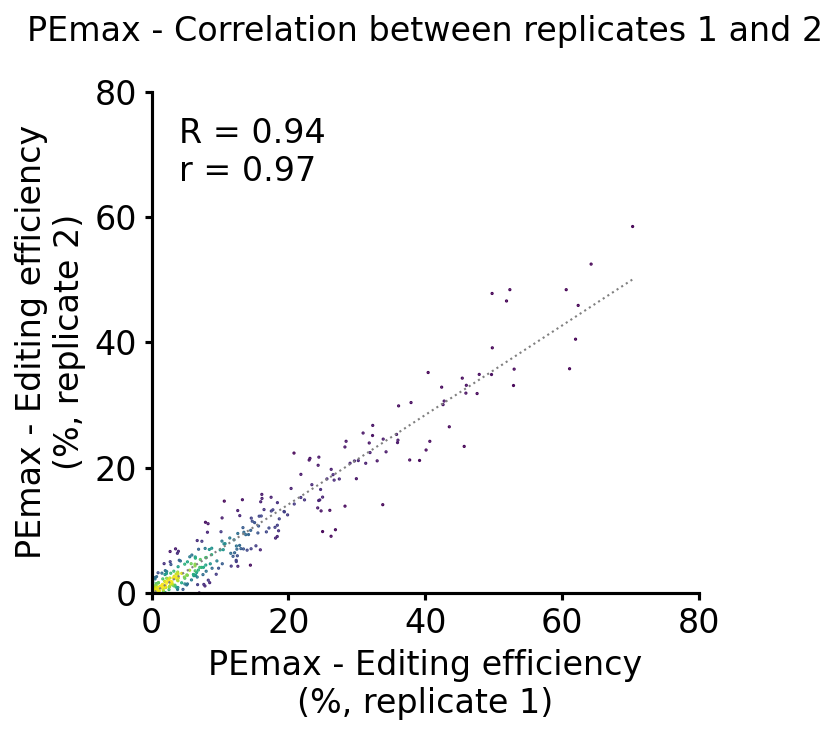

Full length of df: 342
Plotted number after dropping NaNs: 342
Spearman correlation: 0.9411761721583286
Pearson correlation: 0.9673645006356063


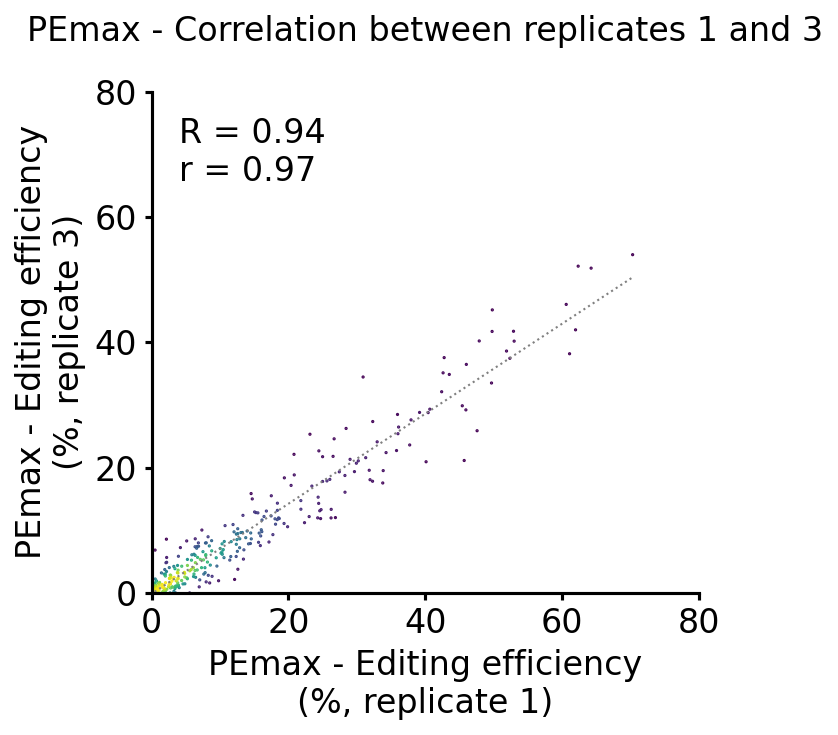

Full length of df: 342
Plotted number after dropping NaNs: 342
Spearman correlation: 0.92601321420549
Pearson correlation: 0.9644862318885831


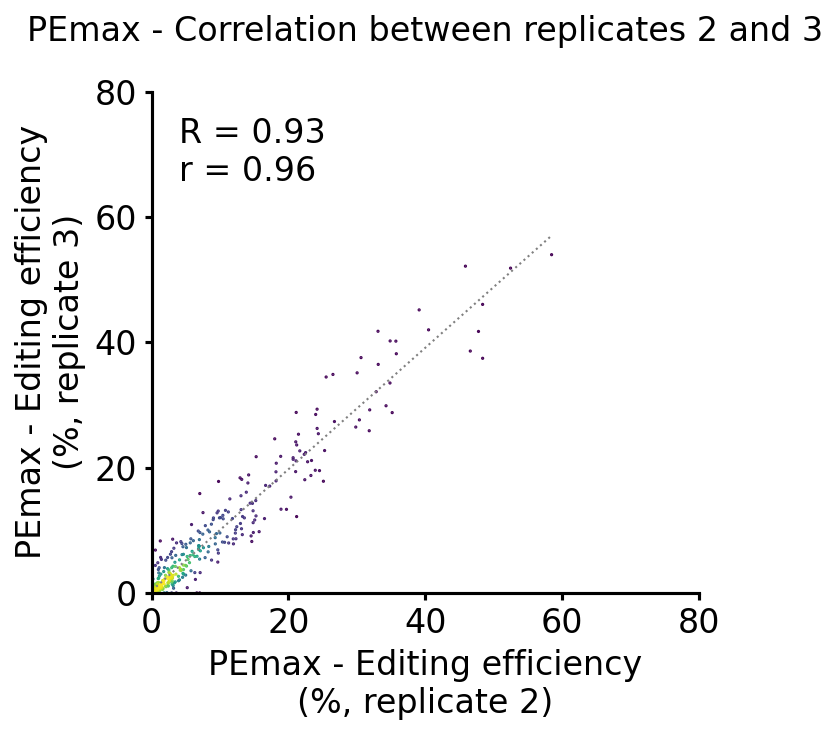

Full length of df: 341
Plotted number after dropping NaNs: 341
Spearman correlation: 0.9514272873644932
Pearson correlation: 0.9606925228589382


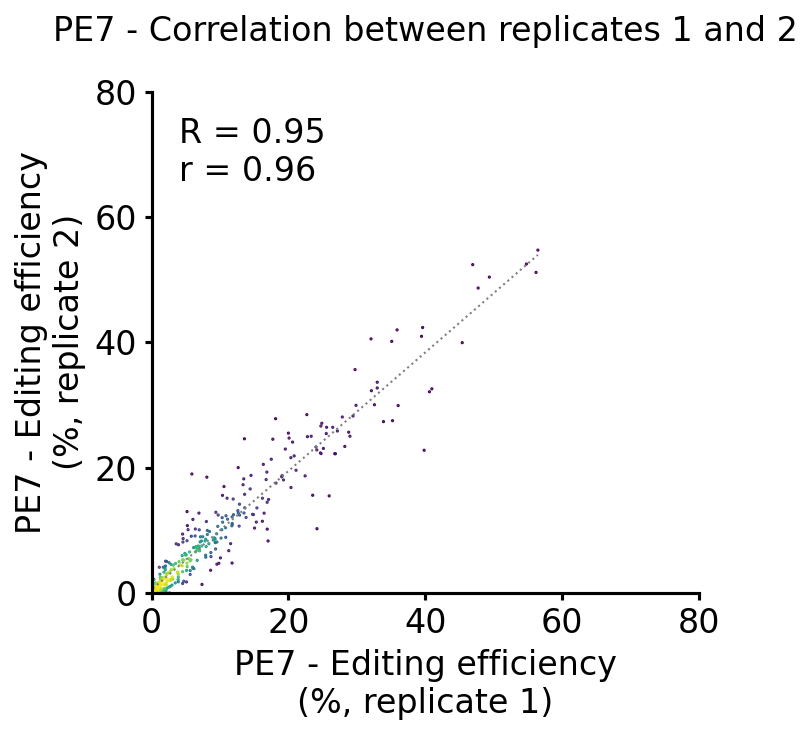

Full length of df: 341
Plotted number after dropping NaNs: 341
Spearman correlation: 0.9429074583026409
Pearson correlation: 0.962608370012553


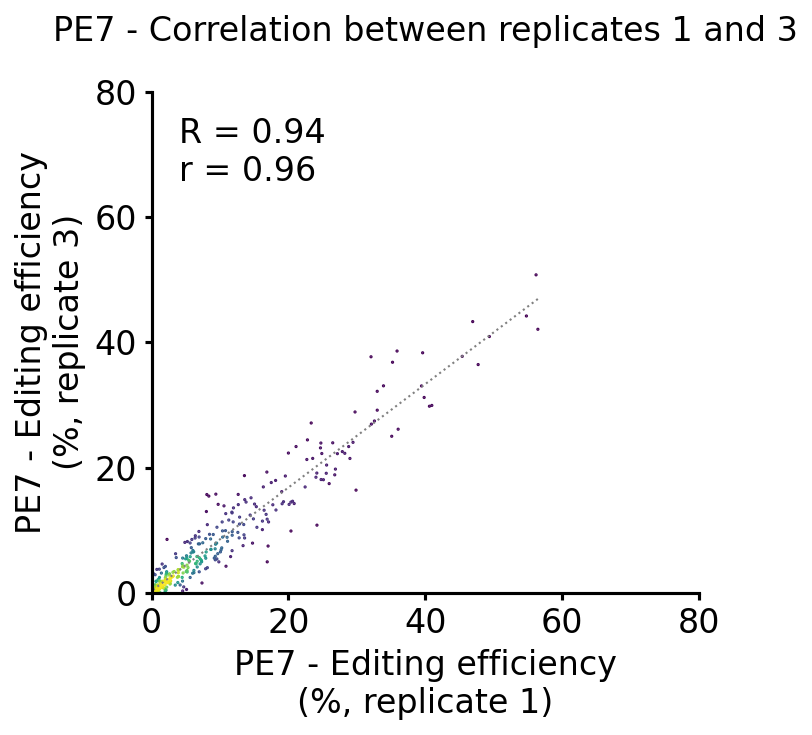

Full length of df: 341
Plotted number after dropping NaNs: 341
Spearman correlation: 0.9448454334042329
Pearson correlation: 0.9612680383802473


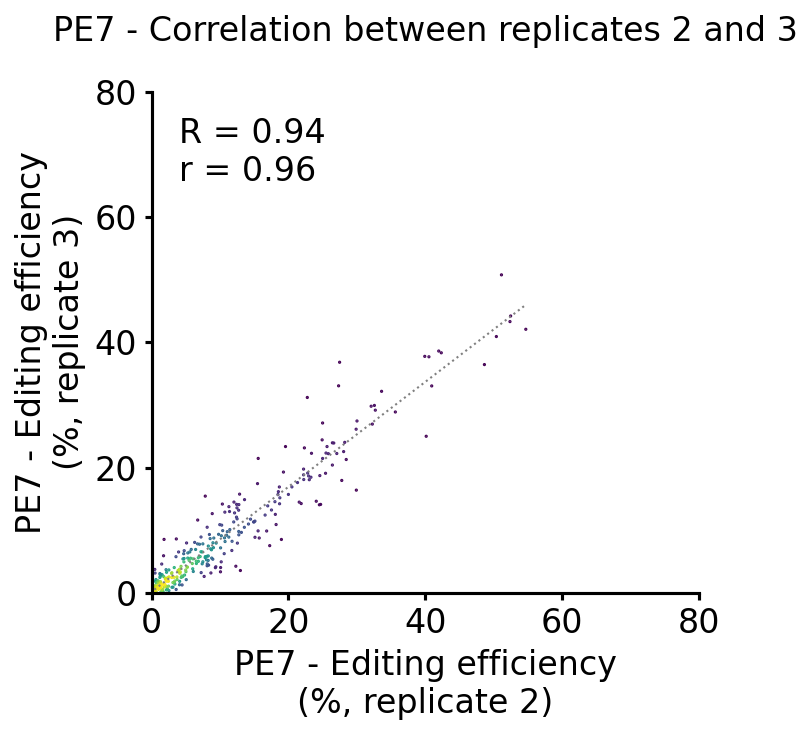

In [10]:
interested_columns = [library_name+'_Pemax_1_percentageedited_corrected_individual',
                      library_name+'_Pemax_2_percentageedited_corrected_individual',
                      library_name+'_Pemax_3_percentageedited_corrected_individual']

clean_templatedf = templatedf.dropna(subset=interested_columns)

rep1eff = clean_templatedf[library_name+'_Pemax_1_percentageedited_corrected_individual'].reset_index(drop=True)
rep2eff = clean_templatedf[library_name+'_Pemax_2_percentageedited_corrected_individual'].reset_index(drop=True)
rep3eff = clean_templatedf[library_name+'_Pemax_3_percentageedited_corrected_individual'].reset_index(drop=True)

create_scatter_plot(clean_templatedf, library_name+'_Pemax_1_percentageedited_corrected_individual', library_name+'_Pemax_2_percentageedited_corrected_individual', 'PEmax - Correlation between replicates 1 and 2\n', 'PEmax - Editing efficiency\n(%, replicate 1)', 'PEmax - Editing efficiency\n(%, replicate 2)', xlim=80, ylim=80)
create_scatter_plot(clean_templatedf, library_name+'_Pemax_1_percentageedited_corrected_individual', library_name+'_Pemax_3_percentageedited_corrected_individual', 'PEmax - Correlation between replicates 1 and 3\n', 'PEmax - Editing efficiency\n(%, replicate 1)', 'PEmax - Editing efficiency\n(%, replicate 3)', xlim=80, ylim=80)
create_scatter_plot(clean_templatedf, library_name+'_Pemax_2_percentageedited_corrected_individual', library_name+'_Pemax_3_percentageedited_corrected_individual', 'PEmax - Correlation between replicates 2 and 3\n', 'PEmax - Editing efficiency\n(%, replicate 2)', 'PEmax - Editing efficiency\n(%, replicate 3)', xlim=80, ylim=80)

interested_columns = [library_name+'_PE7_1_percentageedited_corrected_individual',
                      library_name+'_PE7_2_percentageedited_corrected_individual',
                      library_name+'_PE7_3_percentageedited_corrected_individual']

clean_templatedf = templatedf.dropna(subset=interested_columns)

rep1eff = clean_templatedf[library_name+'_PE7_1_percentageedited_corrected_individual'].reset_index(drop=True)
rep2eff = clean_templatedf[library_name+'_PE7_2_percentageedited_corrected_individual'].reset_index(drop=True)
rep3eff = clean_templatedf[library_name+'_PE7_3_percentageedited_corrected_individual'].reset_index(drop=True)

create_scatter_plot(clean_templatedf, library_name+'_PE7_1_percentageedited_corrected_individual', library_name+'_PE7_2_percentageedited_corrected_individual', 'PE7 - Correlation between replicates 1 and 2\n', 'PE7 - Editing efficiency\n(%, replicate 1)', 'PE7 - Editing efficiency\n(%, replicate 2)', xlim=80, ylim=80)
create_scatter_plot(clean_templatedf, library_name+'_PE7_1_percentageedited_corrected_individual', library_name+'_PE7_3_percentageedited_corrected_individual', 'PE7 - Correlation between replicates 1 and 3\n', 'PE7 - Editing efficiency\n(%, replicate 1)', 'PE7 - Editing efficiency\n(%, replicate 3)', xlim=80, ylim=80)
create_scatter_plot(clean_templatedf, library_name+'_PE7_2_percentageedited_corrected_individual', library_name+'_PE7_3_percentageedited_corrected_individual', 'PE7 - Correlation between replicates 2 and 3\n', 'PE7 - Editing efficiency\n(%, replicate 2)', 'PE7 - Editing efficiency\n(%, replicate 3)', xlim=80, ylim=80)

### Bystander vs Original Plots

In [11]:
fix_ori_names = ['MC4R_Q273_pKP047_71','MC4R_Q273_pKP048_4','MC4R_Q273_pKP051_2','MC4R_Q273_peg1_1','MC4R_Q273_peg2_2','MC4R_Q273_peg3_42']

basename = []
for index, row in templatedf.iterrows():
    uniquename = row['uniquename']
    if uniquename in fix_ori_names:
        basename.append(uniquename)
        continue
    if "original" in uniquename:
        basename.append('_'.join(uniquename.split('_')[:-2]))
    else:
        basename.append('_'.join(uniquename.split('_')[:-3]))

templatedf['basename'] = basename

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy import stats
import seaborn as sns

# Style settings (matching your existing functions)
lsize = 14
titlesize = 16
axesthickness = 1.5
plt.rcParams['axes.linewidth'] = axesthickness
pdffonttpye = 42
psfonttype = 42
fontfamily = 'DejaVu Sans'
mpl.rcParams['pdf.fonttype'] = pdffonttpye
mpl.rcParams['ps.fonttype'] = psfonttype
mpl.rcParams['font.family'] = fontfamily


def create_violin_plot(df, column, categories, category_col, title, xlabel, ylabel, 
                      ylim=None, savepath=None, palette=None, add_boxplot=True):
    """
    Create a violin plot with similar styling to the other plots.
    
    Parameters:
    -----------
    df : pandas DataFrame
        DataFrame containing the data to plot
    column : str
        Column name containing the values to plot
    categories : list
        List of categories to include
    category_col : str
        Column name containing the category information
    title : str
        Title for the plot
    xlabel : str
        X-axis label
    ylabel : str
        Y-axis label
    ylim : tuple, optional
        Y-axis limits (min, max)
    savepath : str, optional
        If provided, save the plot to this path
    palette : list or dict, optional
        Colors for the different categories
    add_boxplot : bool, optional
        Whether to overlay a boxplot on the violin plot
        
    Returns:
    --------
    None : Displays or saves the plot
    """
    # Reset to matplotlib defaults first
    plt.rcdefaults()

    # Apply custom styling
    plt.rcParams['axes.linewidth'] = axesthickness
    mpl.rcParams['pdf.fonttype'] = pdffonttpye
    mpl.rcParams['ps.fonttype'] = psfonttype
    mpl.rcParams['font.family'] = fontfamily

    # Filter data
    plot_df = df[df[category_col].isin(categories)].copy()
    plot_df = plot_df[[category_col, column]].dropna()
    
    print(f"Full length of df: {len(df)}")
    print(f"Plotted number after filtering categories and dropping NaNs: {len(plot_df)}")
    
    if len(plot_df) == 0:
        raise ValueError(f"No data to plot for column {column} after filtering and dropping NaNs.")
    
    # Create figure
    fig, ax = plt.subplots(figsize=(5 + 0.5*len(categories), 5), dpi=150)
    
    # Create violin plot
    violin_parts = ax.violinplot(
        [plot_df[plot_df[category_col] == cat][column].values for cat in categories],
        showmeans=False, showmedians=False, showextrema=False
    )
    
    # Customize violin plot appearance
    for i, pc in enumerate(violin_parts['bodies']):
        if palette:
            color = palette[i] if isinstance(palette, list) else palette.get(categories[i], 'lightgrey')
        else:
            color = f'C{i}'
        pc.set_facecolor(color)
        pc.set_edgecolor('black')
        pc.set_alpha(0.7)
        pc.set_linewidth(1)
    
    # Add box plot if requested
    if add_boxplot:
        boxprops = dict(linestyle='-', linewidth=1.5, color='black')
        whiskerprops = dict(linestyle='-', linewidth=1.5, color='black')
        medianprops = dict(linestyle='-', linewidth=2, color='black')
        meanprops = dict(marker='o', markeredgecolor='black', markerfacecolor='white')
        
        ax.boxplot(
            [plot_df[plot_df[category_col] == cat][column].values for cat in categories],
            positions=range(1, len(categories) + 1),
            widths=0.15, patch_artist=False, showfliers=False,
            boxprops=boxprops, whiskerprops=whiskerprops, 
            medianprops=medianprops, meanprops=meanprops,
            showmeans=True
        )
    
    # Set title and labels
    ax.set_title(title, fontsize=titlesize)
    ax.set_xlabel(xlabel, fontsize=lsize)
    ax.set_ylabel(ylabel, fontsize=lsize)
    
    # Set axis limits
    if ylim:
        ax.set_ylim(ylim)
    
    # Set x-ticks
    ax.set_xticks(range(1, len(categories) + 1))
    ax.set_xticklabels(categories)
    
    # Set tick parameters
    ax.tick_params(axis='x', labelsize=lsize, width=1.5)
    ax.tick_params(axis='y', labelsize=lsize, width=1.5)
    
    # Remove top and right spines
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    
    plt.tight_layout()
    if savepath:
        plt.savefig(savepath, dpi=300, bbox_inches='tight')
    plt.show()
    
    # Print summary statistics for each category
    print("\nSummary Statistics:")
    for cat in categories:
        cat_data = plot_df[plot_df[category_col] == cat][column]
        print(f"\n{cat}:")
        print(f"  Count: {len(cat_data)}")
        print(f"  Mean: {cat_data.mean():.2f}")
        print(f"  Median: {cat_data.median():.2f}")
        print(f"  Std Dev: {cat_data.std():.2f}")


def create_bar_plot(x_data, y_data, title, xlabel, ylabel, 
                    yerr=None, ylim=None, xticks=None, xticklabels=None,
                    bar_color='#C5DEFF', highlight_bars=None, highlight_color=None,
                    add_scatter=False, savepath=None):
    """
    Create a bar plot with similar styling to the other plots.
    
    Parameters:
    -----------
    x_data : list or array
        X-coordinates for the bars (typically indices)
    y_data : list or array
        Heights of the bars. Can be either:
        - Simple list of values (e.g., [10, 20, 30])
        - List of lists, where each inner list represents individual data points 
          (e.g., [[9, 10, 11], [19, 20, 21], [29, 30, 31]])
          In this case, bar heights will be the means of each group
    title : str
        Title for the plot
    xlabel : str
        X-axis label
    ylabel : str
        Y-axis label
    yerr : list or array, optional
        Error bar heights. If None and y_data contains lists, standard error will be calculated
    ylim : tuple, optional
        Y-axis limits (min, max)
    xticks : list or array, optional
        Positions for x-ticks
    xticklabels : list, optional
        Labels for x-ticks
    bar_color : str, optional
        Color for the bars (default: '#C5DEFF')
    highlight_bars : list, optional
        Indices of bars to highlight
    highlight_color : str, optional
        Color for highlighted bars
    add_scatter : bool, optional
        Whether to add scatter points (only works if y_data contains lists of values)
    savepath : str, optional
        If provided, save the plot to this path
    
    Returns:
    --------
    None : Displays or saves the plot
    """
    # Reset to matplotlib defaults first
    plt.rcdefaults()

    # Apply custom styling
    plt.rcParams['axes.linewidth'] = axesthickness
    mpl.rcParams['pdf.fonttype'] = pdffonttpye
    mpl.rcParams['ps.fonttype'] = psfonttype
    mpl.rcParams['font.family'] = fontfamily
    
    # Create figure
    fig, ax = plt.subplots(figsize=(max(5, len(x_data) * 0.8), 4), dpi=150)
    
    # Set bar kwargs based on the example
    bar_kwargs_copy = {'edgecolor': '#000000', 'capsize': 4, 'linewidth': 1.5}
    
    # Check if y_data contains lists (for scatter plotting)
    has_individual_points = isinstance(y_data[0], (list, np.ndarray))
    
    # If y_data contains individual points, calculate means and standard errors
    if has_individual_points:
        heights = [np.mean(group) for group in y_data]
        
        # Calculate standard errors if yerr not provided
        if yerr is None:
            yerr = [stats.sem(group) if len(group) > 1 else 0 for group in y_data]
    else:
        heights = y_data
    
    # Create bar plot
    bars = ax.bar(x_data, heights, yerr=yerr, color=bar_color, **bar_kwargs_copy)
    
    # Highlight specific bars if requested
    if highlight_bars is not None and highlight_color is not None:
        for idx in highlight_bars:
            bars[idx].set_facecolor(highlight_color)
    
    # Add scatter points if requested and if we have individual data points
    if add_scatter and has_individual_points:
        for i, group in enumerate(y_data):
            # Calculate x positions for scatter points
            x = np.random.normal(x_data[i], 0.1, size=len(group))
            ax.scatter(x, group, s=8, color='black', edgecolors='face', alpha=0.4, zorder=2)
    
    # Set title and labels
    ax.set_title(title, fontsize=titlesize)
    ax.set_xlabel(xlabel, fontsize=lsize)
    ax.set_ylabel(ylabel, fontsize=lsize)
    
    # Set axis limits
    if ylim:
        ax.set_ylim(ylim)
    
    # Set x-ticks
    if xticks is not None:
        ax.set_xticks(xticks)
    else:
        ax.set_xticks(x_data)
    
    if xticklabels is not None:
        ax.set_xticklabels(xticklabels, rotation=0, ha='center')
    
    # Set tick parameters
    ax.tick_params(axis='x', labelsize=lsize, width=1.5)
    ax.tick_params(axis='y', labelsize=lsize, width=1.5)
    
    # Remove top and right spines
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    
    plt.tight_layout()
    if savepath:
        plt.savefig(savepath, dpi=300, bbox_inches='tight')
    plt.show()

In [13]:
templatedf
# templatedf.basename.unique()
# templatedf['bestPEmax_per_basename'] = templatedf.groupby('basename')[library_name+'_Pemax_averageedited'].transform('max')
# templatedf['bestPE7_per_basename'] = templatedf.groupby('basename')[library_name+'_PE7_averageedited'].transform('max')

# do this above but by just labelling the best one with True and the rest with False
templatedf['bestPEmax_per_basename'] = templatedf.groupby('basename')[library_name+'_Pemax_averageedited'].transform(lambda x: x == x.max())
templatedf['bestPE7_per_basename'] = templatedf.groupby('basename')[library_name+'_PE7_averageedited'].transform(lambda x: x == x.max())
templatedf.sort_values(by=['basename'])


,Unnamed: 0.1,analysis_bucket,MC4R-focused_PE7_averageedited,MC4R-focused_Pemax_averageedited,uniquename,ori_byst,Filename,Unnamed: 0,Original_Sequence,Edited-Sequences,...,MC4R-focused_Pemax_3_percentageedited_corrected_individual,MC4R-focused_Pemax_3_percentageunintended_corrected_individual,MC4R-focused_Pemax_3_percentageintermediate_corrected_individual,MC4R-focused_Pemax_3_percentageunedited_corrected_individual,MC4R-focused_Pemax_averageunedited,MC4R-focused_Pemax_averageunintended,MC4R-focused_Pemax_averageintermediate,basename,bestPEmax_per_basename,bestPE7_per_basename
0,0,MC4R_1,23.352677,23.357267,MC4R_Q273_pKP047_71,ori,MC4R_Q273_pKP047,NaN,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,...,19.356133,2.086158,NaN,NaN,75.478575,1.164157,NaN,MC4R_Q273_pKP047_71,True,True
1,1,MC4R_1,21.350799,31.398274,MC4R_Q273_pKP048_4,byst,MC4R_Q273_pKP048,NaN,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,...,29.323308,5.998787,NaN,NaN,64.825802,3.775924,NaN,MC4R_Q273_pKP048_4,True,True
2,2,MC4R_1,19.645095,23.316064,MC4R_Q273_pKP051_2,byst,MC4R_Q273_pKP051,NaN,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,...,25.324675,4.738030,NaN,NaN,67.914426,8.769510,NaN,MC4R_Q273_pKP051_2,True,True
3,3,MC4R_1,27.237424,35.683196,MC4R_Q273_peg1_1,ori,MC4R_Q273_peg1,NaN,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,...,29.210526,2.546513,NaN,NaN,62.003382,2.313422,NaN,MC4R_Q273_peg1_1,True,True
4,4,MC4R_1,18.991796,18.033682,MC4R_Q273_peg2_2,byst,MC4R_Q273_peg2,NaN,TCTTGACTCCGGAGGGCATAAATGAGAGGGTCGATGACGGCGTTAC...,TCTTGACTCCGGAGGGCATAAATGAGAGGGTCGATGACGGCGTTAC...,...,13.356164,8.072917,NaN,NaN,75.325684,6.640634,NaN,MC4R_Q273_peg2_2,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
331,331,MC4R_1,3.531706,6.895169,NM_005912.3(MC4R):c.973C>A_(p.Leu325Ile)_origi...,ori,NM_005912.3(MC4R)_c.973C_A_(p.Leu325Ile)_origi...,454.0,CCATATTGTGTGTGCTTCATGTCTCACTTTAACTTGTATCTCATAC...,CCATATTGTGTGTGCTTCATGTCTCACTTTAACTTGTATCTCATAC...,...,2.145923,1.295756,NaN,NaN,92.267558,0.837273,NaN,NM_005912.3(MC4R):c.973C>A_(p.Leu325Ile),False,False
333,333,MC4R_1,2.359292,2.904836,NM_005912.3(MC4R):c.983T>A_(p.Leu328Ter)_origi...,ori,NM_005912.3(MC4R)_c.983T_A_(p.Leu328Ter)_origi...,410.0,GTGTGCTTCATGTCTCACTTTAACTTGTATCTCATACTGATCATGT...,GTGTGCTTCATGTCTCACTTTAACTTGTATCTCATACTGATCATGT...,...,4.379562,-0.221396,NaN,NaN,97.095164,0.000000,NaN,NM_005912.3(MC4R):c.983T>A_(p.Leu328Ter),False,False
332,332,MC4R_1,2.551258,3.497475,NM_005912.3(MC4R):c.983T>A_(p.Leu328Ter)_origi...,ori,NM_005912.3(MC4R)_c.983T_A_(p.Leu328Ter)_origi...,444.0,GTGTGCTTCATGTCTCACTTTAACTTGTATCTCATACTGATCATGT...,GTGTGCTTCATGTCTCACTTTAACTTGTATCTCATACTGATCATGT...,...,4.885764,-2.517370,NaN,NaN,96.502525,0.000000,NaN,NM_005912.3(MC4R):c.983T>A_(p.Leu328Ter),False,False
152,152,MC4R_1,6.027057,6.308523,NM_005912.3(MC4R):c.983T>A_(p.Leu328Ter)_TA_ct_1,byst,NM_005912.3(MC4R):c.983T>A_(p.Leu328Ter)_TA_ct...,444.0,GTGTGCTTCATGTCTCACTTTAACTTGTATCTCATACTGATCATGT...,GTGTGCTTCATGTCTCACTTTAACTTGTATCTCATACTGATCATGT...,...,4.278075,-2.042565,NaN,NaN,93.691477,0.000000,NaN,NM_005912.3(MC4R):c.983T>A_(p.Leu328Ter),True,True


In [14]:
templatedf

,Unnamed: 0.1,analysis_bucket,MC4R-focused_PE7_averageedited,MC4R-focused_Pemax_averageedited,uniquename,ori_byst,Filename,Unnamed: 0,Original_Sequence,Edited-Sequences,...,MC4R-focused_Pemax_3_percentageedited_corrected_individual,MC4R-focused_Pemax_3_percentageunintended_corrected_individual,MC4R-focused_Pemax_3_percentageintermediate_corrected_individual,MC4R-focused_Pemax_3_percentageunedited_corrected_individual,MC4R-focused_Pemax_averageunedited,MC4R-focused_Pemax_averageunintended,MC4R-focused_Pemax_averageintermediate,basename,bestPEmax_per_basename,bestPE7_per_basename
0,0,MC4R_1,23.352677,23.357267,MC4R_Q273_pKP047_71,ori,MC4R_Q273_pKP047,NaN,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,...,19.356133,2.086158,NaN,NaN,75.478575,1.164157,NaN,MC4R_Q273_pKP047_71,True,True
1,1,MC4R_1,21.350799,31.398274,MC4R_Q273_pKP048_4,byst,MC4R_Q273_pKP048,NaN,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,...,29.323308,5.998787,NaN,NaN,64.825802,3.775924,NaN,MC4R_Q273_pKP048_4,True,True
2,2,MC4R_1,19.645095,23.316064,MC4R_Q273_pKP051_2,byst,MC4R_Q273_pKP051,NaN,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,...,25.324675,4.738030,NaN,NaN,67.914426,8.769510,NaN,MC4R_Q273_pKP051_2,True,True
3,3,MC4R_1,27.237424,35.683196,MC4R_Q273_peg1_1,ori,MC4R_Q273_peg1,NaN,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,...,29.210526,2.546513,NaN,NaN,62.003382,2.313422,NaN,MC4R_Q273_peg1_1,True,True
4,4,MC4R_1,18.991796,18.033682,MC4R_Q273_peg2_2,byst,MC4R_Q273_peg2,NaN,TCTTGACTCCGGAGGGCATAAATGAGAGGGTCGATGACGGCGTTAC...,TCTTGACTCCGGAGGGCATAAATGAGAGGGTCGATGACGGCGTTAC...,...,13.356164,8.072917,NaN,NaN,75.325684,6.640634,NaN,MC4R_Q273_peg2_2,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
376,376,MC4R_1,1.614219,1.195258,NM_005912.3(MC4R):c.929G>A_(p.Arg310Lys)_AAGAA...,byst,NM_005912.3(MC4R):c.929G>A_(p.Arg310Lys)_AAGAA...,294.0,TTGCAGAAGTACAATATTCAGGTAGGGTAAGAGTGAAAAAGTCTCT...,TTGCAGAAGTACAATATTCAGGTAGGGTAAGAGTGAAAAAGTCTCT...,...,0.881612,0.102922,NaN,NaN,97.873618,0.931124,NaN,NM_005912.3(MC4R):c.929G>A_(p.Arg310Lys),False,False
377,377,MC4R_1,7.833215,9.751747,NM_005912.3(MC4R):c.422T>G_(p.Leu141Arg)_CTGCG...,byst,NM_005912.3(MC4R):c.422T>G_(p.Leu141Arg)_CTGCG...,142.0,ACTACTATCTGAGTAAATGATGAACAAAATGCCTGAAACCGTGCAA...,ACTACTATCTGAGTAAATGATGAACAAAATGCCTGAAACCGTGCAA...,...,9.375000,1.393115,NaN,NaN,89.301304,0.946949,NaN,NM_005912.3(MC4R):c.422T>G_(p.Leu141Arg),False,False
378,378,MC4R_1,7.342507,7.620713,NM_005912.3(MC4R):c.812G>A_(p.Cys271Tyr)_TTA_c...,byst,NM_005912.3(MC4R):c.812G>A_(p.Cys271Tyr)_TTA_c...,291.0,GGGATAGCAACAGATGATCTCTTTGAAGGTTTTCCTCAGTTCTTGA...,GGGATAGCAACAGATGATCTCTTTGAAGGTTTTCCTCAGTTCTTGA...,...,7.496252,2.090316,NaN,NaN,89.428773,2.950515,NaN,NM_005912.3(MC4R):c.812G>A_(p.Cys271Tyr),False,False
379,379,MC4R_1,4.547501,3.993366,NM_005912.3(MC4R):c.935C>G_(p.Thr312Ser)_GAAAA...,byst,NM_005912.3(MC4R):c.935C>G_(p.Thr312Ser)_GAAAA...,294.0,TTCCTCCACTTAATATTCTACATCTCTTGTCCTCAGAATCCATATT...,TTCCTCCACTTAATATTCTACATCTCTTGTCCTCAGAATCCATATT...,...,3.017241,0.841282,NaN,NaN,95.356680,0.649954,NaN,NM_005912.3(MC4R):c.935C>G_(p.Thr312Ser),False,False


Full length of df: 381
Plotted number after filtering categories and dropping NaNs: 342


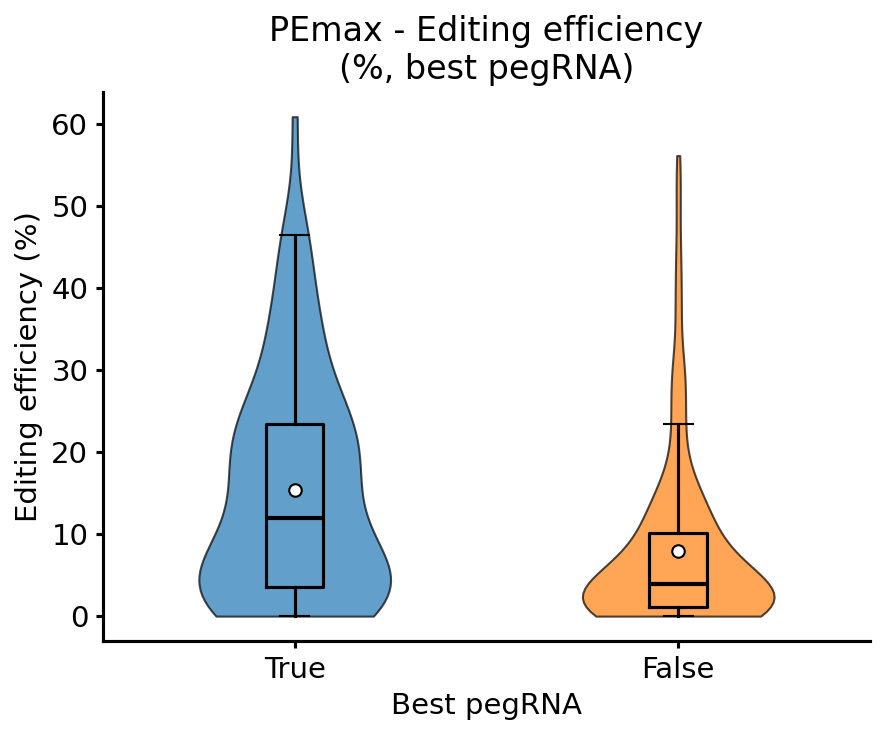


Summary Statistics:

True:
  Count: 96
  Mean: 15.45
  Median: 11.92
  Std Dev: 13.78

False:
  Count: 246
  Mean: 7.90
  Median: 3.96
  Std Dev: 10.50
Full length of df: 381
Plotted number after filtering categories and dropping NaNs: 341


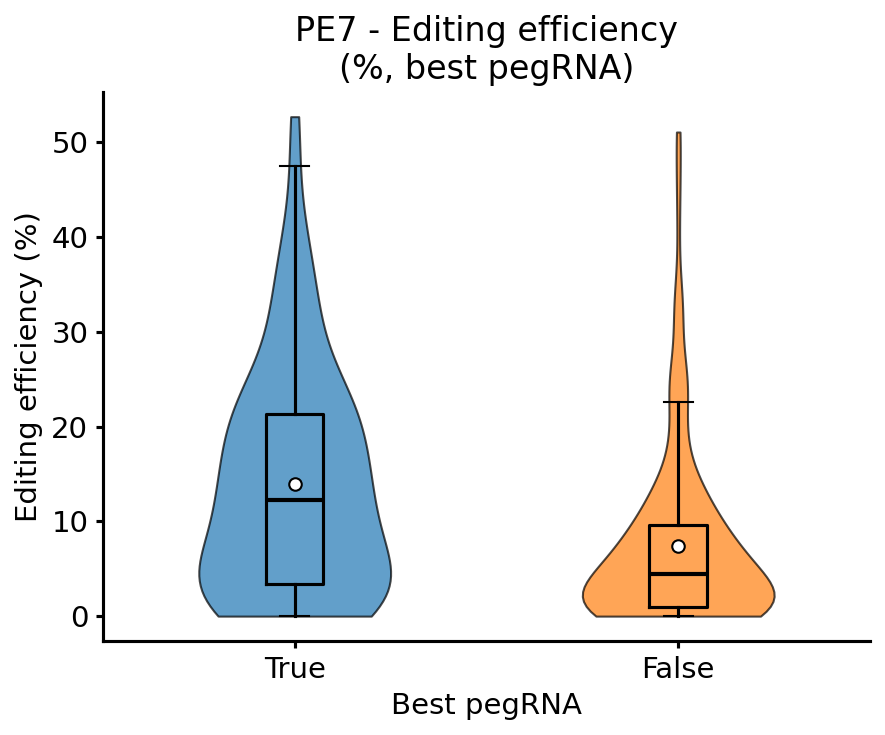


Summary Statistics:

True:
  Count: 96
  Mean: 13.92
  Median: 12.26
  Std Dev: 11.94

False:
  Count: 245
  Mean: 7.40
  Median: 4.42
  Std Dev: 9.38


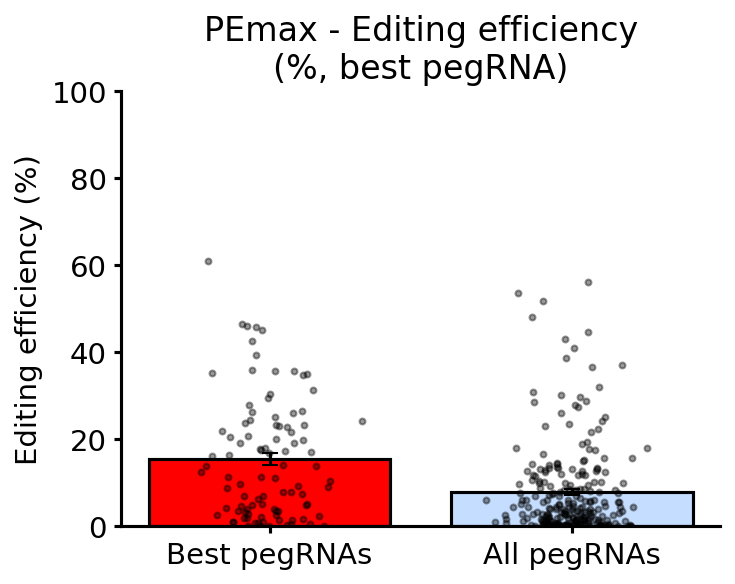

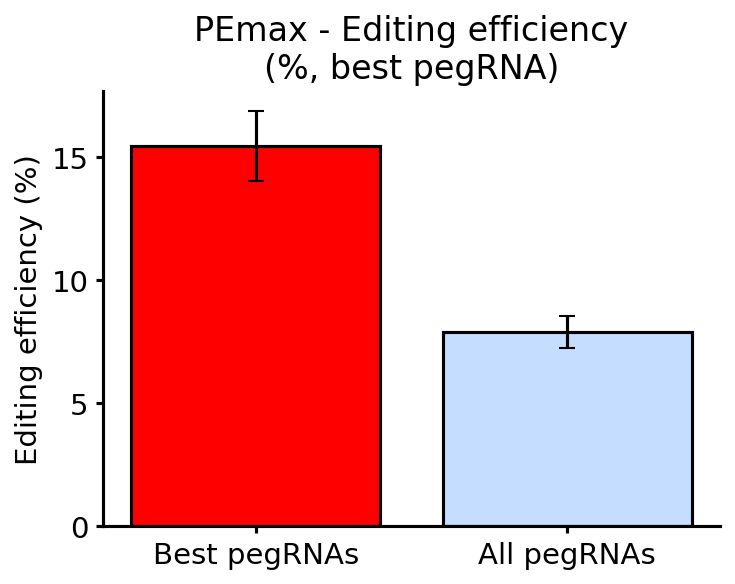

In [15]:
# create a 2 violin plots (one for PEmax one for PE7) both with one violin with only the best pegRNAs and one with all pegRNAs

# create a violin plot for PEmax
create_violin_plot(templatedf, library_name+'_Pemax_averageedited', 
                    categories=[True, False], category_col='bestPEmax_per_basename',
                    title='PEmax - Editing efficiency\n(%, best pegRNA)',
                    xlabel='Best pegRNA', ylabel='Editing efficiency (%)')

# create a violin plot for PE7
create_violin_plot(templatedf, library_name+'_PE7_averageedited', 
                    categories=[True, False], category_col='bestPE7_per_basename',
                    title='PE7 - Editing efficiency\n(%, best pegRNA)',
                    xlabel='Best pegRNA', ylabel='Editing efficiency (%)')

# Group data by bestPEmax_per_basename (True/False)
true_group = templatedf[templatedf['bestPEmax_per_basename'] == True][library_name+'_Pemax_averageedited'].dropna().tolist()
false_group = templatedf[templatedf['bestPEmax_per_basename'] == False][library_name+'_Pemax_averageedited'].dropna().tolist()

# Create y_data as a list of lists (required for scatter points)
y_data = [true_group, false_group]

# Create bar plot with the same groups as violin plot
create_bar_plot(
    x_data=[0, 1],  # Two positions for the two groups
    y_data=y_data,  # List of lists for the scatter points
    title='PEmax - Editing efficiency\n(%, best pegRNA)',
    xlabel='', ylabel='Editing efficiency (%)',
    ylim=(0, 100),
    xticklabels=['Best pegRNAs', 'All pegRNAs'],  # Labels for each group
    bar_color='#C5DEFF',
    highlight_bars=[0],  # Highlight the first bar (True group)
    highlight_color='red',
    add_scatter=True  # Add scatter points
)

# Create bar plot with the same groups as violin plot
create_bar_plot(
    x_data=[0, 1],  # Two positions for the two groups
    y_data=y_data,  # List of lists for the scatter points
    title='PEmax - Editing efficiency\n(%, best pegRNA)',
    xlabel='', ylabel='Editing efficiency (%)',
    xticklabels=['Best pegRNAs', 'All pegRNAs'],  # Labels for each group
    bar_color='#C5DEFF',
    highlight_bars=[0],  # Highlight the first bar (True group)
    highlight_color='red'
)

In [16]:
templatedf

,Unnamed: 0.1,analysis_bucket,MC4R-focused_PE7_averageedited,MC4R-focused_Pemax_averageedited,uniquename,ori_byst,Filename,Unnamed: 0,Original_Sequence,Edited-Sequences,...,MC4R-focused_Pemax_3_percentageedited_corrected_individual,MC4R-focused_Pemax_3_percentageunintended_corrected_individual,MC4R-focused_Pemax_3_percentageintermediate_corrected_individual,MC4R-focused_Pemax_3_percentageunedited_corrected_individual,MC4R-focused_Pemax_averageunedited,MC4R-focused_Pemax_averageunintended,MC4R-focused_Pemax_averageintermediate,basename,bestPEmax_per_basename,bestPE7_per_basename
0,0,MC4R_1,23.352677,23.357267,MC4R_Q273_pKP047_71,ori,MC4R_Q273_pKP047,NaN,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,...,19.356133,2.086158,NaN,NaN,75.478575,1.164157,NaN,MC4R_Q273_pKP047_71,True,True
1,1,MC4R_1,21.350799,31.398274,MC4R_Q273_pKP048_4,byst,MC4R_Q273_pKP048,NaN,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,...,29.323308,5.998787,NaN,NaN,64.825802,3.775924,NaN,MC4R_Q273_pKP048_4,True,True
2,2,MC4R_1,19.645095,23.316064,MC4R_Q273_pKP051_2,byst,MC4R_Q273_pKP051,NaN,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,...,25.324675,4.738030,NaN,NaN,67.914426,8.769510,NaN,MC4R_Q273_pKP051_2,True,True
3,3,MC4R_1,27.237424,35.683196,MC4R_Q273_peg1_1,ori,MC4R_Q273_peg1,NaN,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,...,29.210526,2.546513,NaN,NaN,62.003382,2.313422,NaN,MC4R_Q273_peg1_1,True,True
4,4,MC4R_1,18.991796,18.033682,MC4R_Q273_peg2_2,byst,MC4R_Q273_peg2,NaN,TCTTGACTCCGGAGGGCATAAATGAGAGGGTCGATGACGGCGTTAC...,TCTTGACTCCGGAGGGCATAAATGAGAGGGTCGATGACGGCGTTAC...,...,13.356164,8.072917,NaN,NaN,75.325684,6.640634,NaN,MC4R_Q273_peg2_2,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
376,376,MC4R_1,1.614219,1.195258,NM_005912.3(MC4R):c.929G>A_(p.Arg310Lys)_AAGAA...,byst,NM_005912.3(MC4R):c.929G>A_(p.Arg310Lys)_AAGAA...,294.0,TTGCAGAAGTACAATATTCAGGTAGGGTAAGAGTGAAAAAGTCTCT...,TTGCAGAAGTACAATATTCAGGTAGGGTAAGAGTGAAAAAGTCTCT...,...,0.881612,0.102922,NaN,NaN,97.873618,0.931124,NaN,NM_005912.3(MC4R):c.929G>A_(p.Arg310Lys),False,False
377,377,MC4R_1,7.833215,9.751747,NM_005912.3(MC4R):c.422T>G_(p.Leu141Arg)_CTGCG...,byst,NM_005912.3(MC4R):c.422T>G_(p.Leu141Arg)_CTGCG...,142.0,ACTACTATCTGAGTAAATGATGAACAAAATGCCTGAAACCGTGCAA...,ACTACTATCTGAGTAAATGATGAACAAAATGCCTGAAACCGTGCAA...,...,9.375000,1.393115,NaN,NaN,89.301304,0.946949,NaN,NM_005912.3(MC4R):c.422T>G_(p.Leu141Arg),False,False
378,378,MC4R_1,7.342507,7.620713,NM_005912.3(MC4R):c.812G>A_(p.Cys271Tyr)_TTA_c...,byst,NM_005912.3(MC4R):c.812G>A_(p.Cys271Tyr)_TTA_c...,291.0,GGGATAGCAACAGATGATCTCTTTGAAGGTTTTCCTCAGTTCTTGA...,GGGATAGCAACAGATGATCTCTTTGAAGGTTTTCCTCAGTTCTTGA...,...,7.496252,2.090316,NaN,NaN,89.428773,2.950515,NaN,NM_005912.3(MC4R):c.812G>A_(p.Cys271Tyr),False,False
379,379,MC4R_1,4.547501,3.993366,NM_005912.3(MC4R):c.935C>G_(p.Thr312Ser)_GAAAA...,byst,NM_005912.3(MC4R):c.935C>G_(p.Thr312Ser)_GAAAA...,294.0,TTCCTCCACTTAATATTCTACATCTCTTGTCCTCAGAATCCATATT...,TTCCTCCACTTAATATTCTACATCTCTTGTCCTCAGAATCCATATT...,...,3.017241,0.841282,NaN,NaN,95.356680,0.649954,NaN,NM_005912.3(MC4R):c.935C>G_(p.Thr312Ser),False,False


Full length of df: 381
Plotted number after filtering categories and dropping NaNs: 342


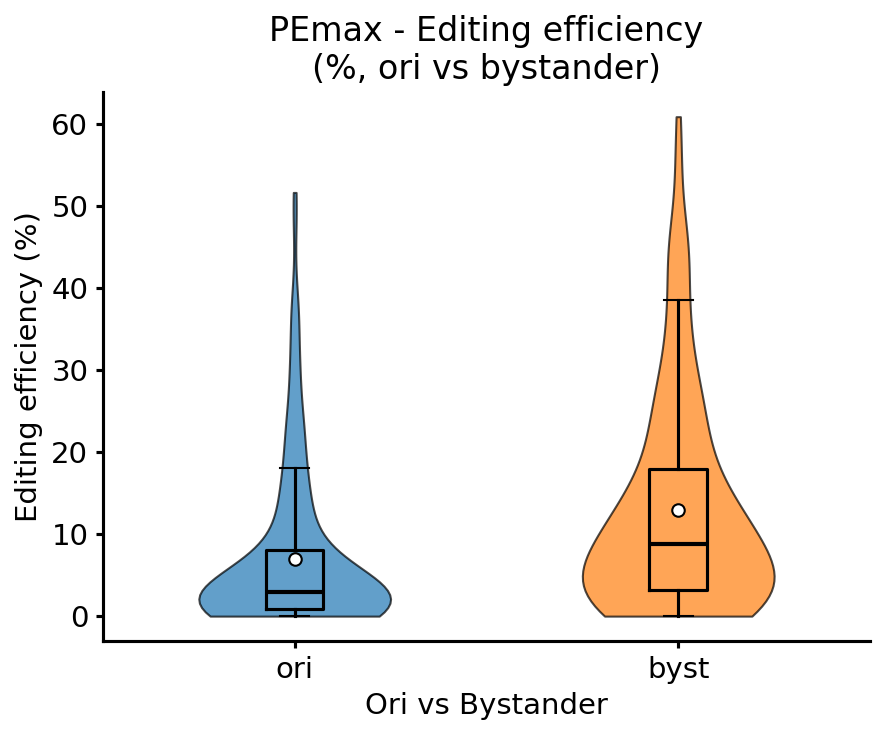


Summary Statistics:

ori:
  Count: 167
  Mean: 6.96
  Median: 2.90
  Std Dev: 9.84

byst:
  Count: 175
  Mean: 12.93
  Median: 8.75
  Std Dev: 13.11
Full length of df: 381
Plotted number after filtering categories and dropping NaNs: 341


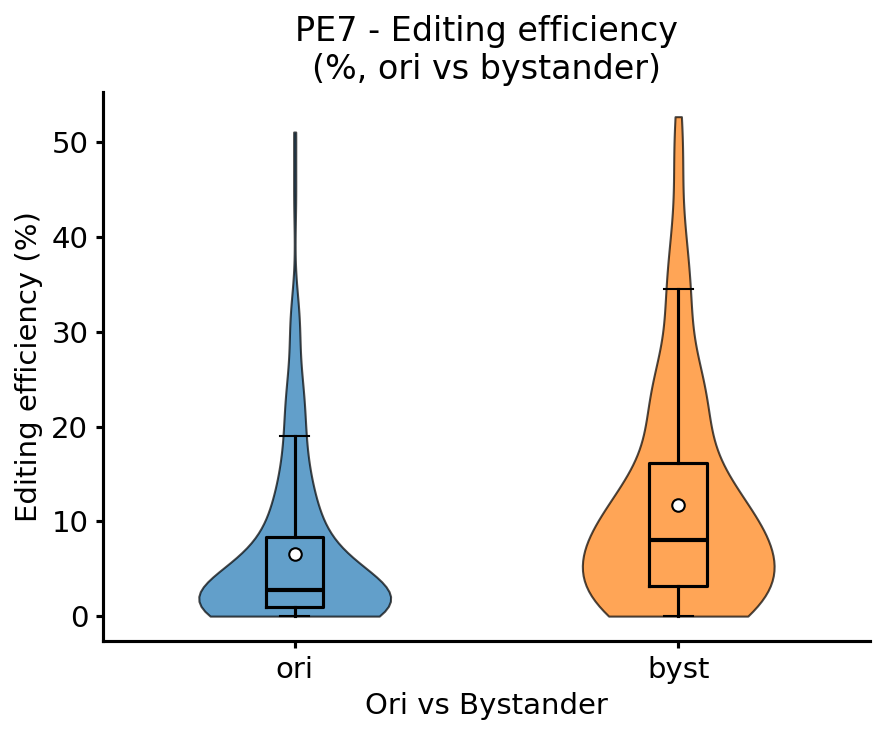


Summary Statistics:

ori:
  Count: 165
  Mean: 6.54
  Median: 2.76
  Std Dev: 8.82

byst:
  Count: 176
  Mean: 11.76
  Median: 8.06
  Std Dev: 11.42


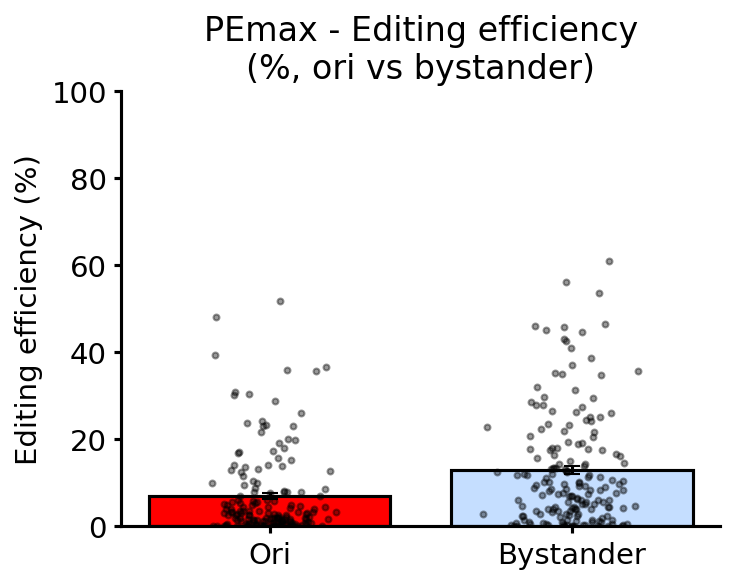

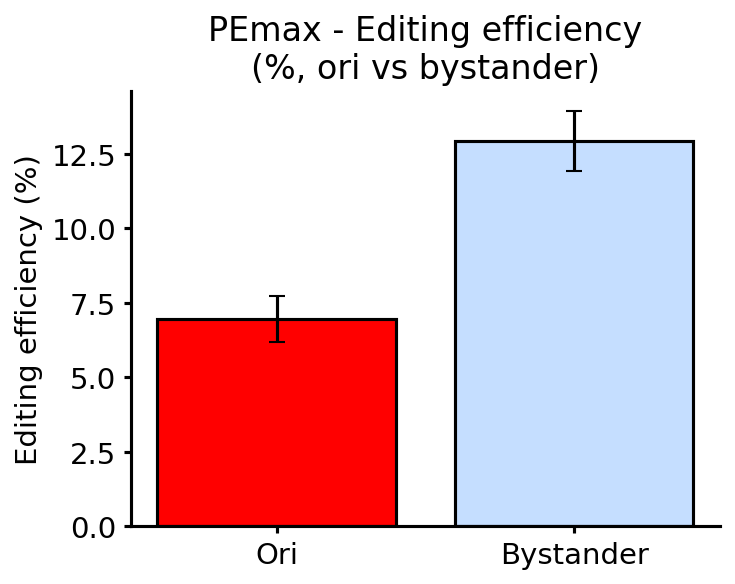

In [17]:
# Ok we want to do the same thing but now for ori_byst column that contains either "ori" or "byst"
# 
# create a violin plot for PEmax
create_violin_plot(templatedf, library_name+'_Pemax_averageedited', 
                    categories=['ori', 'byst'], category_col='ori_byst',
                    title='PEmax - Editing efficiency\n(%, ori vs bystander)',
                    xlabel='Ori vs Bystander', ylabel='Editing efficiency (%)')
# create a violin plot for PE7
create_violin_plot(templatedf, library_name+'_PE7_averageedited', 
                    categories=['ori', 'byst'], category_col='ori_byst',
                    title='PE7 - Editing efficiency\n(%, ori vs bystander)',
                    xlabel='Ori vs Bystander', ylabel='Editing efficiency (%)')
# Group data by ori_byst (ori/bystander)
ori_group = templatedf[templatedf['ori_byst'] == 'ori'][library_name+'_Pemax_averageedited'].dropna().tolist()
byst_group = templatedf[templatedf['ori_byst'] == 'byst'][library_name+'_Pemax_averageedited'].dropna().tolist()
# Create y_data as a list of lists (required for scatter points)
y_data = [ori_group, byst_group]
# Create bar plot with the same groups as violin plot
create_bar_plot(
    x_data=[0, 1],  # Two positions for the two groups
    y_data=y_data,  # List of lists for the scatter points
    title='PEmax - Editing efficiency\n(%, ori vs bystander)',
    xlabel='', ylabel='Editing efficiency (%)',
    ylim=(0, 100),
    xticklabels=['Ori', 'Bystander'],  # Labels for each group
    bar_color='#C5DEFF',
    highlight_bars=[0],  # Highlight the first bar (ori group)
    highlight_color='red',
    add_scatter=True  # Add scatter points
)
# Create bar plot with the same groups as violin plot
create_bar_plot(
    x_data=[0, 1],  # Two positions for the two groups
    y_data=y_data,  # List of lists for the scatter points
    title='PEmax - Editing efficiency\n(%, ori vs bystander)',
    xlabel='', ylabel='Editing efficiency (%)',
    xticklabels=['Ori', 'Bystander'],  # Labels for each group
    bar_color='#C5DEFF',
    highlight_bars=[0],  # Highlight the first bar (ori group)
    highlight_color='red'
) 

Creating violin plots for best ori vs best byst per target...
Full length of df: 172
Plotted number after filtering categories and dropping NaNs: 162


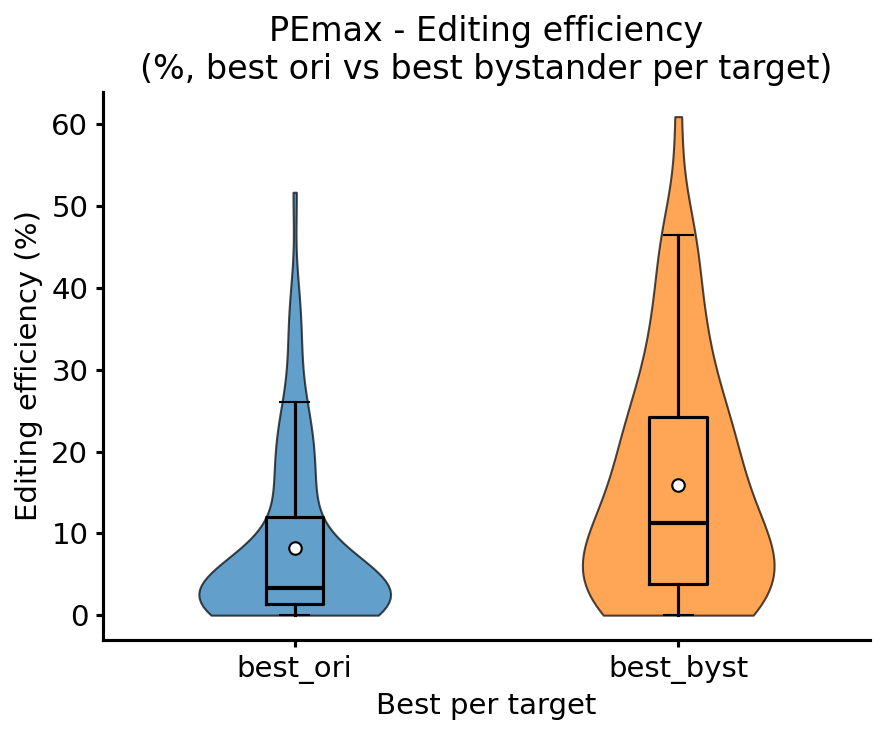


Summary Statistics:

best_ori:
  Count: 90
  Mean: 8.21
  Median: 3.32
  Std Dev: 10.58

best_byst:
  Count: 72
  Mean: 15.86
  Median: 11.32
  Std Dev: 14.37
Full length of df: 172
Plotted number after filtering categories and dropping NaNs: 162


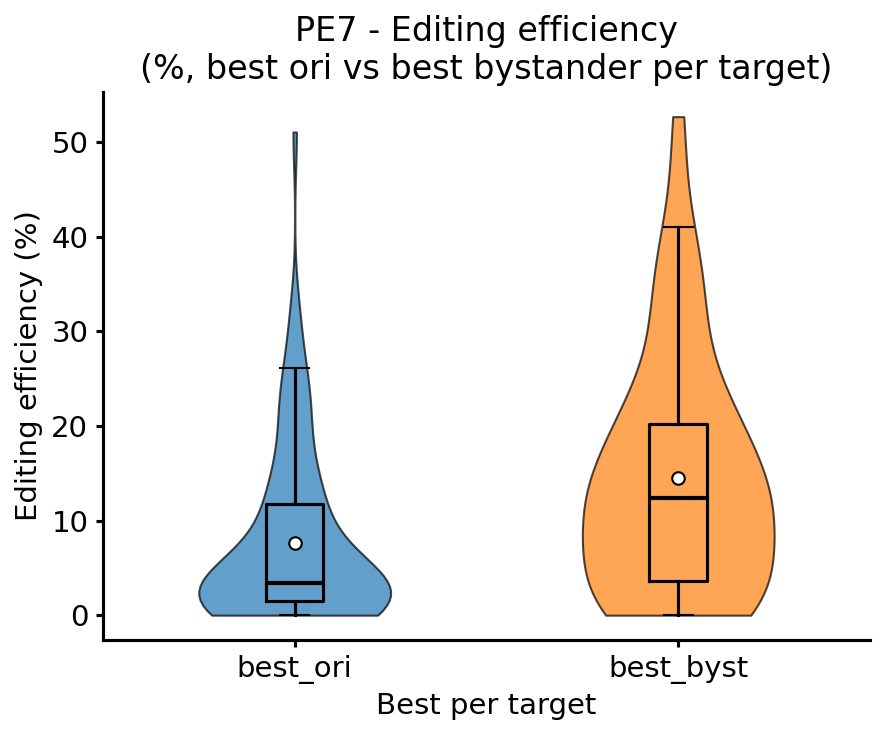


Summary Statistics:

best_ori:
  Count: 90
  Mean: 7.58
  Median: 3.40
  Std Dev: 9.31

best_byst:
  Count: 72
  Mean: 14.45
  Median: 12.34
  Std Dev: 12.53
Creating bar plots for best ori vs best byst per target...
Best ori per target (PEmax): 90 targets
Best byst per target (PEmax): 72 targets


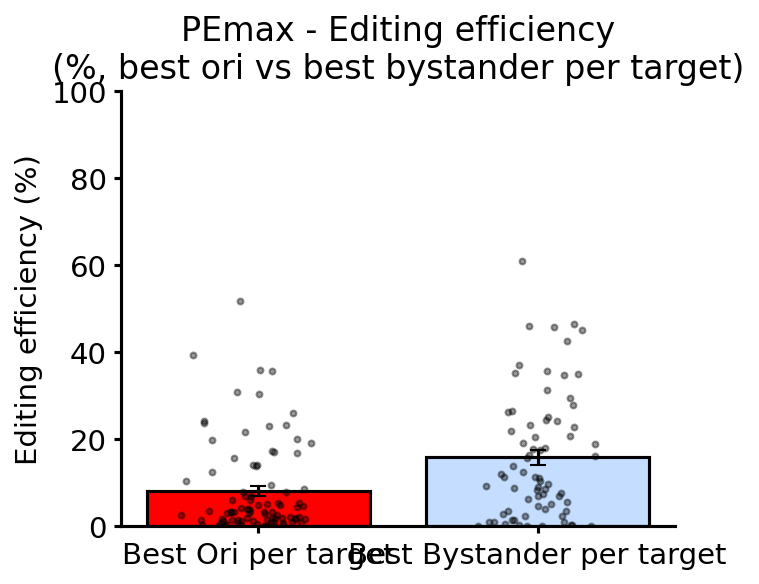

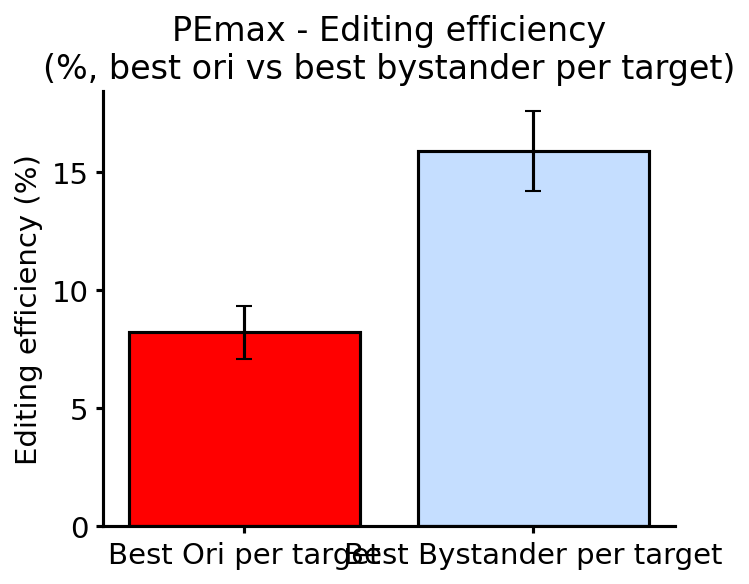

Best ori per target (PE7): 90 targets
Best byst per target (PE7): 72 targets


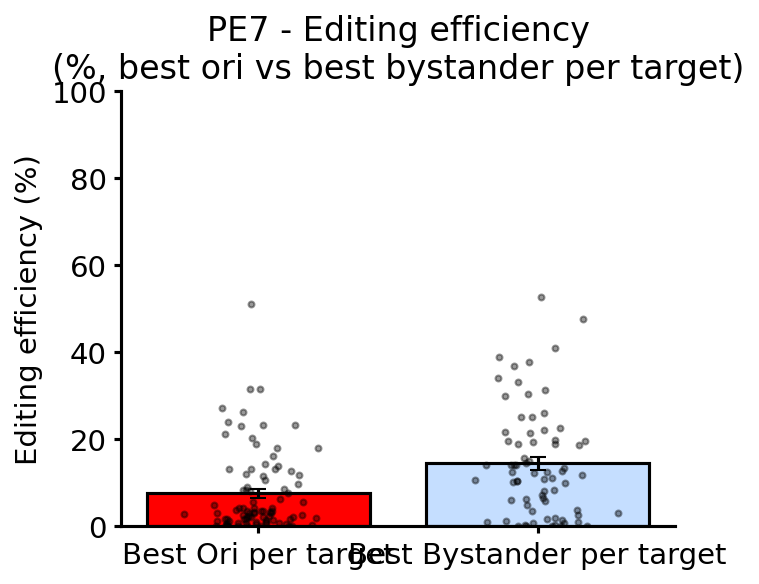

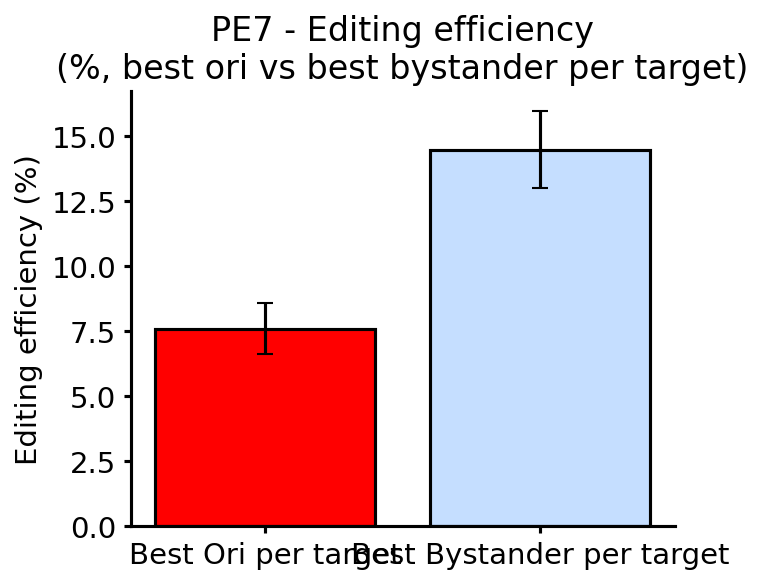

In [19]:
# Create violin plots for best ori vs best byst per target
print("Creating violin plots for best ori vs best byst per target...")

# For the violin plots, we need to create a temporary dataframe with the best values per target
best_ori_per_target = templatedf[templatedf['ori_byst'] == 'ori'].groupby('basename')[library_name+'_Pemax_averageedited'].max().reset_index()
best_ori_per_target['category'] = 'best_ori'
best_byst_per_target = templatedf[templatedf['ori_byst'] == 'byst'].groupby('basename')[library_name+'_Pemax_averageedited'].max().reset_index()
best_byst_per_target['category'] = 'best_byst'

# Combine for PEmax violin plot
combined_best_pemax = pd.concat([
    best_ori_per_target[['basename', library_name+'_Pemax_averageedited', 'category']],
    best_byst_per_target[['basename', library_name+'_Pemax_averageedited', 'category']]
])

# Create violin plot for PEmax
create_violin_plot(combined_best_pemax, library_name+'_Pemax_averageedited', 
                    categories=['best_ori', 'best_byst'], category_col='category',
                    title='PEmax - Editing efficiency\n(%, best ori vs best bystander per target)',
                    xlabel='Best per target', ylabel='Editing efficiency (%)')

# Do the same for PE7
best_ori_per_target_pe7 = templatedf[templatedf['ori_byst'] == 'ori'].groupby('basename')[library_name+'_PE7_averageedited'].max().reset_index()
best_ori_per_target_pe7['category'] = 'best_ori'
best_byst_per_target_pe7 = templatedf[templatedf['ori_byst'] == 'byst'].groupby('basename')[library_name+'_PE7_averageedited'].max().reset_index()
best_byst_per_target_pe7['category'] = 'best_byst'

# Combine for PE7 violin plot
combined_best_pe7 = pd.concat([
    best_ori_per_target_pe7[['basename', library_name+'_PE7_averageedited', 'category']],
    best_byst_per_target_pe7[['basename', library_name+'_PE7_averageedited', 'category']]
])

# Create violin plot for PE7
create_violin_plot(combined_best_pe7, library_name+'_PE7_averageedited', 
                    categories=['best_ori', 'best_byst'], category_col='category',
                    title='PE7 - Editing efficiency\n(%, best ori vs best bystander per target)',
                    xlabel='Best per target', ylabel='Editing efficiency (%)')

print("Creating bar plots for best ori vs best byst per target...")

# Group data by ori_byst and basename, then get the best (max) value for each target - PEmax
best_ori_group_pemax = templatedf[templatedf['ori_byst'] == 'ori'].groupby('basename')[library_name+'_Pemax_averageedited'].max().dropna().tolist()
best_byst_group_pemax = templatedf[templatedf['ori_byst'] == 'byst'].groupby('basename')[library_name+'_Pemax_averageedited'].max().dropna().tolist()

print(f"Best ori per target (PEmax): {len(best_ori_group_pemax)} targets")
print(f"Best byst per target (PEmax): {len(best_byst_group_pemax)} targets")

# Create y_data as a list of lists (required for scatter points) - PEmax
y_data_pemax = [best_ori_group_pemax, best_byst_group_pemax]

# Create bar plot with scatter points - PEmax
create_bar_plot(
    x_data=[0, 1],  # Two positions for the two groups
    y_data=y_data_pemax,  # List of lists for the scatter points
    title='PEmax - Editing efficiency\n(%, best ori vs best bystander per target)',
    xlabel='', ylabel='Editing efficiency (%)',
    ylim=(0, 100),
    xticklabels=['Best Ori per target', 'Best Bystander per target'],  # Labels for each group
    bar_color='#C5DEFF',
    highlight_bars=[0],  # Highlight the first bar (best ori group)
    highlight_color='red',
    add_scatter=True  # Add scatter points
)

# Create bar plot without scatter points - PEmax
create_bar_plot(
    x_data=[0, 1],  # Two positions for the two groups
    y_data=y_data_pemax,  # List of lists for the scatter points
    title='PEmax - Editing efficiency\n(%, best ori vs best bystander per target)',
    xlabel='', ylabel='Editing efficiency (%)',
    xticklabels=['Best Ori per target', 'Best Bystander per target'],  # Labels for each group
    bar_color='#C5DEFF',
    highlight_bars=[0],  # Highlight the first bar (best ori group)
    highlight_color='red'
)

# Group data by ori_byst and basename, then get the best (max) value for each target - PE7
best_ori_group_pe7 = templatedf[templatedf['ori_byst'] == 'ori'].groupby('basename')[library_name+'_PE7_averageedited'].max().dropna().tolist()
best_byst_group_pe7 = templatedf[templatedf['ori_byst'] == 'byst'].groupby('basename')[library_name+'_PE7_averageedited'].max().dropna().tolist()

print(f"Best ori per target (PE7): {len(best_ori_group_pe7)} targets")
print(f"Best byst per target (PE7): {len(best_byst_group_pe7)} targets")

# Create y_data as a list of lists (required for scatter points) - PE7
y_data_pe7 = [best_ori_group_pe7, best_byst_group_pe7]

# Create bar plot with scatter points - PE7
create_bar_plot(
    x_data=[0, 1],  # Two positions for the two groups
    y_data=y_data_pe7,  # List of lists for the scatter points
    title='PE7 - Editing efficiency\n(%, best ori vs best bystander per target)',
    xlabel='', ylabel='Editing efficiency (%)',
    ylim=(0, 100),
    xticklabels=['Best Ori per target', 'Best Bystander per target'],  # Labels for each group
    bar_color='#C5DEFF',
    highlight_bars=[0],  # Highlight the first bar (best ori group)
    highlight_color='red',
    add_scatter=True  # Add scatter points
)

# Create bar plot without scatter points - PE7
create_bar_plot(
    x_data=[0, 1],  # Two positions for the two groups
    y_data=y_data_pe7,  # List of lists for the scatter points
    title='PE7 - Editing efficiency\n(%, best ori vs best bystander per target)',
    xlabel='', ylabel='Editing efficiency (%)',
    xticklabels=['Best Ori per target', 'Best Bystander per target'],  # Labels for each group
    bar_color='#C5DEFF',
    highlight_bars=[0],  # Highlight the first bar (best ori group)
    highlight_color='red'
)

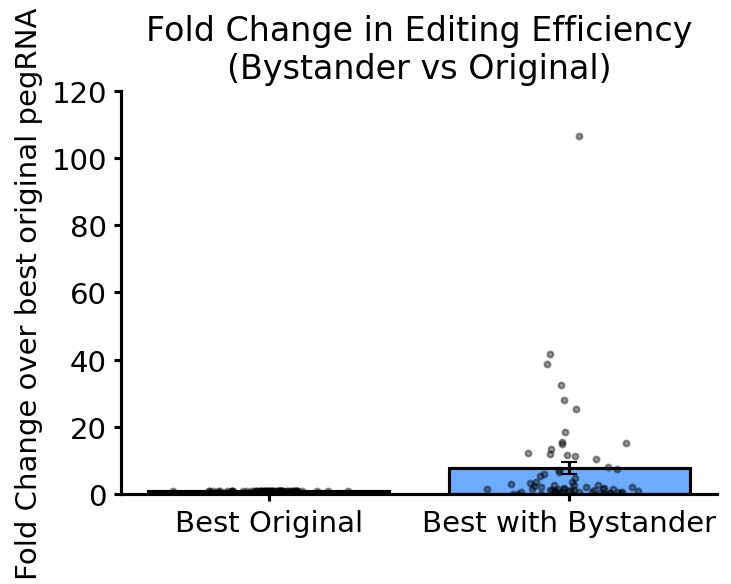

Average fold change: 7.74
Median fold change: 2.07
Minimum fold change: 0.00
Maximum fold change: 106.66
Number of basenames with improvement (>1.0): 48 out of 66


In [20]:
import numpy as np

# Get unique basenames
basenames = templatedf['basename'].unique()

# Initialize lists to store fold changes
fold_changes = []
basename_labels = []

# For each basename, calculate fold change between best ori and best byst
for basename in basenames:
    # Filter for this basename
    basename_df = templatedf[templatedf['basename'] == basename]
    
    # Get best original and best bystander for this basename
    best_ori = basename_df[basename_df['ori_byst'] == 'ori'][library_name+'_Pemax_averageedited'].max()
    best_byst = basename_df[basename_df['ori_byst'] == 'byst'][library_name+'_Pemax_averageedited'].max()
    
    # Calculate fold change if both values exist
    if not np.isnan(best_ori) and not np.isnan(best_byst) and best_ori > 0:
        fold_change = best_byst / best_ori
        fold_changes.append(fold_change)
        basename_labels.append(basename)

# Create fold change bar plot
# First, prepare data for bar plot format:
# 1. A bar for reference at 1.0 (original sequences)
# 2. A bar for average fold change with individual points

# Convert list to array for easier calculations
fold_changes_array = np.array(fold_changes)

# For bar plot format
bar_means = [1.0, np.mean(fold_changes_array)]  # Mean fold change
bar_std = [0, np.std(fold_changes_array)]  # Standard deviation

# Data for scatter points (all original sequences have fold change = 1)
y_data = [[1.0] * len(fold_changes), fold_changes]

# Create bar plot
create_bar_plot(
    x_data=[0, 1],
    y_data=y_data,
    title='Fold Change in Editing Efficiency\n(Bystander vs Original)',
    xlabel='', ylabel='Fold Change over best original pegRNA',
    ylim=(0, 120),  # Dynamic upper limit
    xticklabels=['Best Original\n', 'Best with Bystander'],
    bar_color='#C5DEFF',
    highlight_bars=[1] if np.mean(fold_changes_array) > 1.0 else [],  # Highlight if improvement
    highlight_color='#6eacff',
    add_scatter=True
)

# Print some statistics
print(f"Average fold change: {np.mean(fold_changes_array):.2f}")
print(f"Median fold change: {np.median(fold_changes_array):.2f}")
print(f"Minimum fold change: {np.min(fold_changes_array):.2f}")
print(f"Maximum fold change: {np.max(fold_changes_array):.2f}")
print(f"Number of basenames with improvement (>1.0): {np.sum(fold_changes_array > 1.0)} out of {len(fold_changes_array)}")

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy import stats
import seaborn as sns

# Style settings (matching your existing functions)
lsize = 14
titlesize = 16
axesthickness = 1.5
plt.rcParams['axes.linewidth'] = axesthickness
pdffonttpye = 42
psfonttype = 42
fontfamily = 'DejaVu Sans'
mpl.rcParams['pdf.fonttype'] = pdffonttpye
mpl.rcParams['ps.fonttype'] = psfonttype
mpl.rcParams['font.family'] = fontfamily


def create_violin_plot(df, column, categories, category_col, title, xlabel, ylabel, 
                      ylim=None, savepath=None, palette=None, add_boxplot=True,
                      highlight_row=None, highlight_name=None, highlight_value=None,
                      highlight_color='red', highlight_size=60, highlight_label=None):
    """
    Create a violin plot with similar styling to the other plots.
    
    Parameters:
    -----------
    df : pandas DataFrame
        DataFrame containing the data to plot
    column : str
        Column name containing the values to plot
    categories : list
        List of categories to include
    category_col : str
        Column name containing the category information
    title : str
        Title for the plot
    xlabel : str
        X-axis label
    ylabel : str
        Y-axis label
    ylim : tuple, optional
        Y-axis limits (min, max)
    savepath : str, optional
        If provided, save the plot to this path
    palette : list or dict, optional
        Colors for the different categories
    add_boxplot : bool, optional
        Whether to overlay a boxplot on the violin plot
    highlight_row : int, str, or callable, optional
        Identifier for the row to highlight. Can be:
        - Integer: Row index in the DataFrame
        - String: Value in a column (requires highlight_name to be specified)
        - Callable: Function that takes a row and returns True for the row to highlight
    highlight_name : str, optional
        Column name to look up highlight_row value (if highlight_row is a string)
    highlight_value : float, optional
        Directly specify the value to highlight (alternative to highlight_row)
    highlight_color : str, optional
        Color for the highlighted point (default: 'red')
    highlight_size : int, optional
        Size for the highlighted point (default: 60)
    highlight_label : str, optional
        Label to show in the legend for the highlighted point
        
    Returns:
    --------
    None : Displays or saves the plot
    """
    # Reset to matplotlib defaults first
    plt.rcdefaults()

    # Apply custom styling
    plt.rcParams['axes.linewidth'] = axesthickness
    mpl.rcParams['pdf.fonttype'] = pdffonttpye
    mpl.rcParams['ps.fonttype'] = psfonttype
    mpl.rcParams['font.family'] = fontfamily

    # Filter data
    plot_df = df[df[category_col].isin(categories)].copy()
    plot_df = plot_df[[category_col, column]].dropna()
    
    print(f"Full length of df: {len(df)}")
    print(f"Plotted number after filtering categories and dropping NaNs: {len(plot_df)}")
    
    if len(plot_df) == 0:
        raise ValueError(f"No data to plot for column {column} after filtering and dropping NaNs.")
    
    # Create figure
    fig, ax = plt.subplots(figsize=(5 + 0.5*len(categories), 5), dpi=150)
    
    # Create violin plot
    violin_parts = ax.violinplot(
        [plot_df[plot_df[category_col] == cat][column].values for cat in categories],
        showmeans=False, showmedians=False, showextrema=False
    )
    
    # Customize violin plot appearance
    for i, pc in enumerate(violin_parts['bodies']):
        if palette:
            color = palette[i] if isinstance(palette, list) else palette.get(categories[i], 'lightgrey')
        else:
            color = f'C{i}'
        pc.set_facecolor(color)
        pc.set_edgecolor('black')
        pc.set_alpha(0.7)
        pc.set_linewidth(1)
    
    # Add box plot if requested
    if add_boxplot:
        boxprops = dict(linestyle='-', linewidth=1.5, color='black')
        whiskerprops = dict(linestyle='-', linewidth=1.5, color='black')
        medianprops = dict(linestyle='-', linewidth=2, color='black')
        meanprops = dict(marker='o', markeredgecolor='black', markerfacecolor='white')
        
        ax.boxplot(
            [plot_df[plot_df[category_col] == cat][column].values for cat in categories],
            positions=range(1, len(categories) + 1),
            widths=0.15, patch_artist=False, showfliers=False,
            boxprops=boxprops, whiskerprops=whiskerprops, 
            medianprops=medianprops, meanprops=meanprops,
            showmeans=True
        )
    
    # Highlight a specific point if requested
    highlight_point_added = False
    
    # Find highlight value based on row identification
    if highlight_row is not None:
        # Get the full dataframe with all columns for finding the highlight
        highlight_df = df.copy()
        
        # Find the row to highlight
        if isinstance(highlight_row, int):
            # Row index
            if 0 <= highlight_row < len(highlight_df):
                highlighted_row = highlight_df.iloc[highlight_row]
                if not pd.isna(highlighted_row[column]) and highlighted_row[category_col] in categories:
                    highlight_cat = highlighted_row[category_col]
                    highlight_val = highlighted_row[column]
                    highlight_point_added = True
        elif isinstance(highlight_row, str) and highlight_name is not None:
            # String value in a specific column
            mask = highlight_df[highlight_name] == highlight_row
            if mask.any():
                highlighted_row = highlight_df[mask].iloc[0]
                if not pd.isna(highlighted_row[column]) and highlighted_row[category_col] in categories:
                    highlight_cat = highlighted_row[category_col]
                    highlight_val = highlighted_row[column]
                    highlight_point_added = True
        elif callable(highlight_row):
            # Function that returns True for the row to highlight
            mask = highlight_df.apply(highlight_row, axis=1)
            if mask.any():
                highlighted_row = highlight_df[mask].iloc[0]
                if not pd.isna(highlighted_row[column]) and highlighted_row[category_col] in categories:
                    highlight_cat = highlighted_row[category_col]
                    highlight_val = highlighted_row[column]
                    highlight_point_added = True
    
    # Or use direct value specification
    elif highlight_value is not None and highlight_name is not None:
        # Category must be directly specified for this mode
        if highlight_name in categories:
            highlight_cat = highlight_name
            highlight_val = highlight_value
            highlight_point_added = True
    
    # Add the highlight point if found
    if highlight_point_added:
        cat_index = categories.index(highlight_cat) + 1  # +1 because violin positions start at 1
        scatter = ax.scatter(cat_index, highlight_val, 
                            s=highlight_size, 
                            color=highlight_color, 
                            zorder=10,  # Make sure it's on top
                            edgecolor='black', 
                            linewidth=1,
                            label=highlight_label)
        
        # Add legend if label is provided
        if highlight_label:
            ax.legend(fontsize=lsize-2)
    
    # Set title and labels
    ax.set_title(title, fontsize=titlesize)
    ax.set_xlabel(xlabel, fontsize=lsize)
    ax.set_ylabel(ylabel, fontsize=lsize)
    
    # Set axis limits
    if ylim:
        ax.set_ylim(ylim)
    
    # Set x-ticks
    ax.set_xticks(range(1, len(categories) + 1))
    ax.set_xticklabels(categories)
    
    # Set tick parameters
    ax.tick_params(axis='x', labelsize=lsize, width=1.5)
    ax.tick_params(axis='y', labelsize=lsize, width=1.5)
    
    # Remove top and right spines
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    
    plt.tight_layout()
    if savepath:
        plt.savefig(savepath, dpi=300, bbox_inches='tight')
    plt.show()
    
    # Print summary statistics for each category
    print("\nSummary Statistics:")
    for cat in categories:
        cat_data = plot_df[plot_df[category_col] == cat][column]
        print(f"\n{cat}:")
        print(f"  Count: {len(cat_data)}")
        print(f"  Mean: {cat_data.mean():.2f}")
        print(f"  Median: {cat_data.median():.2f}")
        print(f"  Std Dev: {cat_data.std():.2f}")


def create_bar_plot(x_data, y_data, title, xlabel, ylabel, 
                    yerr=None, ylim=None, xticks=None, xticklabels=None,
                    bar_color='#C5DEFF', highlight_bars=None, highlight_color=None,
                    add_scatter=False, savepath=None):
    """
    Create a bar plot with similar styling to the other plots.
    
    Parameters:
    -----------
    x_data : list or array
        X-coordinates for the bars (typically indices)
    y_data : list or array
        Heights of the bars. Can be either:
        - Simple list of values (e.g., [10, 20, 30])
        - List of lists, where each inner list represents individual data points 
          (e.g., [[9, 10, 11], [19, 20, 21], [29, 30, 31]])
          In this case, bar heights will be the means of each group
    title : str
        Title for the plot
    xlabel : str
        X-axis label
    ylabel : str
        Y-axis label
    yerr : list or array, optional
        Error bar heights. If None and y_data contains lists, standard error will be calculated
    ylim : tuple, optional
        Y-axis limits (min, max)
    xticks : list or array, optional
        Positions for x-ticks
    xticklabels : list, optional
        Labels for x-ticks
    bar_color : str, optional
        Color for the bars (default: '#C5DEFF')
    highlight_bars : list, optional
        Indices of bars to highlight
    highlight_color : str, optional
        Color for highlighted bars
    add_scatter : bool, optional
        Whether to add scatter points (only works if y_data contains lists of values)
    savepath : str, optional
        If provided, save the plot to this path
    
    Returns:
    --------
    None : Displays or saves the plot
    """
    # Reset to matplotlib defaults first
    plt.rcdefaults()

    # Apply custom styling
    plt.rcParams['axes.linewidth'] = axesthickness
    mpl.rcParams['pdf.fonttype'] = pdffonttpye
    mpl.rcParams['ps.fonttype'] = psfonttype
    mpl.rcParams['font.family'] = fontfamily
    
    # Create figure
    fig, ax = plt.subplots(figsize=(max(5, len(x_data) * 0.8), 4), dpi=150)
    
    # Set bar kwargs based on the example
    bar_kwargs_copy = {'edgecolor': '#000000', 'capsize': 4, 'linewidth': 1.5}
    
    # Check if y_data contains lists (for scatter plotting)
    has_individual_points = isinstance(y_data[0], (list, np.ndarray))
    
    # If y_data contains individual points, calculate means and standard errors
    if has_individual_points:
        heights = [np.mean(group) for group in y_data]
        
        # Calculate standard errors if yerr not provided
        if yerr is None:
            yerr = [stats.sem(group) if len(group) > 1 else 0 for group in y_data]
    else:
        heights = y_data
    
    # Create bar plot
    bars = ax.bar(x_data, heights, yerr=yerr, color=bar_color, **bar_kwargs_copy)
    
    # Highlight specific bars if requested
    if highlight_bars is not None and highlight_color is not None:
        for idx in highlight_bars:
            bars[idx].set_facecolor(highlight_color)
    
    # Add scatter points if requested and if we have individual data points
    if add_scatter and has_individual_points:
        for i, group in enumerate(y_data):
            # Calculate x positions for scatter points
            x = np.random.normal(x_data[i], 0.1, size=len(group))
            ax.scatter(x, group, s=8, color='black', edgecolors='face', alpha=0.4, zorder=2)
    
    # Set title and labels
    ax.set_title(title, fontsize=titlesize)
    ax.set_xlabel(xlabel, fontsize=lsize)
    ax.set_ylabel(ylabel, fontsize=lsize)
    
    # Set axis limits
    if ylim:
        ax.set_ylim(ylim)
    
    # Set x-ticks
    if xticks is not None:
        ax.set_xticks(xticks)
    else:
        ax.set_xticks(x_data)
    
    if xticklabels is not None:
        ax.set_xticklabels(xticklabels, rotation=0, ha='center')
    
    # Set tick parameters
    ax.tick_params(axis='x', labelsize=lsize, width=1.5)
    ax.tick_params(axis='y', labelsize=lsize, width=1.5)
    
    # Remove top and right spines
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    
    plt.tight_layout()
    if savepath:
        plt.savefig(savepath, dpi=300, bbox_inches='tight')
    plt.show()


def create_grouped_bar_plot(labels, data, title, xlabel, ylabel, 
                           ylim=None, bar_color='#C5DEFF', final_bar_color=None,
                           highlight_indices=None, add_scatter=False, savepath=None):
    """
    Create a grouped bar plot with similar styling to the plot_comparison function.
    
    Parameters:
    -----------
    labels : list
        Labels for the x-axis categories
    data : list of arrays
        List of data arrays for each category
    title : str
        Title for the plot
    xlabel : str
        X-axis label
    ylabel : str
        Y-axis label
    ylim : tuple, optional
        Y-axis limits (min, max)
    bar_color : str, optional
        Color for the bars (default: '#C5DEFF')
    final_bar_color : str, optional
        Color for highlighted bars (typically the last ones)
    highlight_indices : list, optional
        Indices of bars to highlight (default is last two)
    add_scatter : bool, optional
        Whether to add scatter points for individual values
    savepath : str, optional
        If provided, save the plot to this path
    
    Returns:
    --------
    None : Displays or saves the plot
    """
    # Reset to matplotlib defaults first
    plt.rcdefaults()

    # Apply custom styling
    plt.rcParams['axes.linewidth'] = axesthickness
    mpl.rcParams['pdf.fonttype'] = pdffonttpye
    mpl.rcParams['ps.fonttype'] = psfonttype
    mpl.rcParams['font.family'] = fontfamily
    
    # Create figure with width proportional to the number of bars
    fig, ax = plt.subplots(figsize=(max(9, len(labels) * 1.2), 3), dpi=150)
    
    # Calculate mean and standard deviation
    means = [np.mean(group) for group in data]
    stds = [np.std(group) for group in data]
    
    # Set bar kwargs based on the example
    bar_kwargs_copy = {'edgecolor': '#000000', 'capsize': 4, 'linewidth': 1.5}
    
    # Plot bars
    bar_containers = ax.bar(range(len(labels)), means, yerr=stds, color=bar_color, **bar_kwargs_copy)
    
    # Highlight specific bars if requested
    if highlight_indices is None and final_bar_color is not None:
        # Default: highlight last two bars
        highlight_indices = [-1, -2]
    
    if highlight_indices is not None and final_bar_color is not None:
        for idx in highlight_indices:
            bar_containers[idx].set_facecolor(final_bar_color)
    
    # Add scatter points if requested
    if add_scatter:
        for i, group in enumerate(data):
            # Calculate x positions for scatter points
            x = np.random.normal(i, 0.1, size=len(group))
            ax.scatter(x, group, s=8, color='black', edgecolors='face', alpha=0.4, zorder=2)
    
    # Set title and labels
    ax.set_title(title, fontsize=titlesize)
    ax.set_xlabel(xlabel, fontsize=lsize)
    ax.set_ylabel(ylabel, fontsize=lsize)
    
    # Set axis limits
    if ylim:
        ax.set_ylim(ylim)
    
    # Set x-ticks
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=0, ha='center')
    
    # Set tick parameters
    ax.tick_params(axis='x', labelsize=lsize, width=1.5)
    ax.tick_params(axis='y', labelsize=lsize, width=1.5)
    
    # Remove top and right spines
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    
    plt.tight_layout()
    if savepath:
        plt.savefig(savepath, dpi=300, bbox_inches='tight')
    plt.show()




Full length of df: 381
Plotted number after filtering categories and dropping NaNs: 342


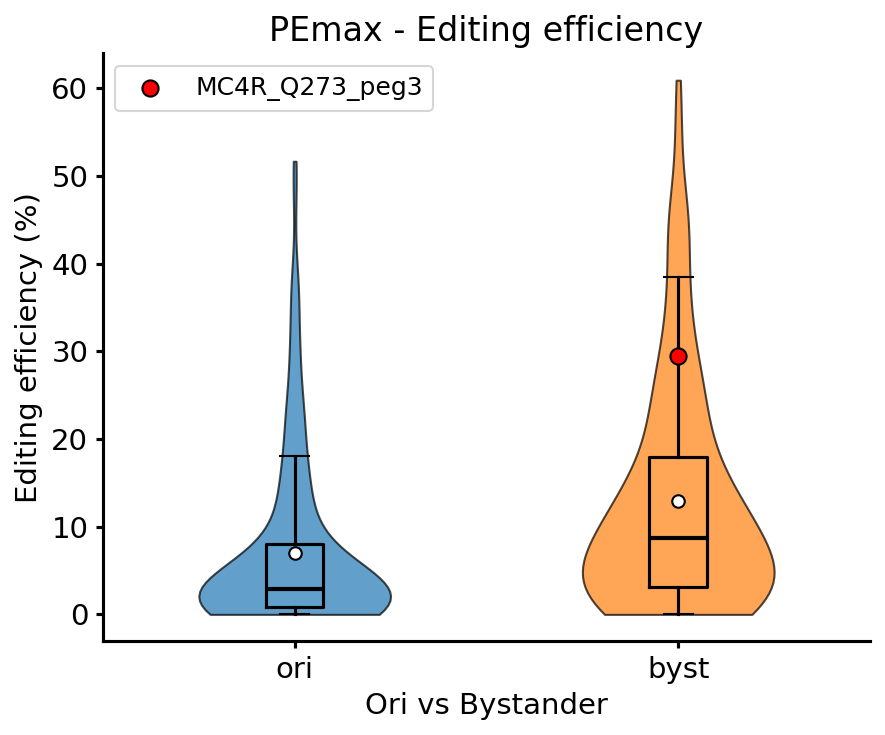


Summary Statistics:

ori:
  Count: 167
  Mean: 6.96
  Median: 2.90
  Std Dev: 9.84

byst:
  Count: 175
  Mean: 12.93
  Median: 8.75
  Std Dev: 13.11


In [22]:
create_violin_plot(templatedf, library_name+'_Pemax_averageedited', 
                   categories=['ori', 'byst'], category_col='ori_byst',
                   title='PEmax - Editing efficiency',
                   xlabel='Ori vs Bystander', ylabel='Editing efficiency (%)',
                   highlight_row='MC4R_Q273_peg3_42', highlight_name='uniquename',
                   highlight_label='MC4R_Q273_peg3')

In [23]:
templatedf.head(10)

,Unnamed: 0.1,analysis_bucket,MC4R-focused_PE7_averageedited,MC4R-focused_Pemax_averageedited,uniquename,ori_byst,Filename,Unnamed: 0,Original_Sequence,Edited-Sequences,...,MC4R-focused_Pemax_3_percentageedited_corrected_individual,MC4R-focused_Pemax_3_percentageunintended_corrected_individual,MC4R-focused_Pemax_3_percentageintermediate_corrected_individual,MC4R-focused_Pemax_3_percentageunedited_corrected_individual,MC4R-focused_Pemax_averageunedited,MC4R-focused_Pemax_averageunintended,MC4R-focused_Pemax_averageintermediate,basename,bestPEmax_per_basename,bestPE7_per_basename
0,0,MC4R_1,23.352677,23.357267,MC4R_Q273_pKP047_71,ori,MC4R_Q273_pKP047,NaN,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,...,19.356133,2.086158,NaN,NaN,75.478575,1.164157,NaN,MC4R_Q273_pKP047_71,True,True
1,1,MC4R_1,21.350799,31.398274,MC4R_Q273_pKP048_4,byst,MC4R_Q273_pKP048,NaN,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,...,29.323308,5.998787,NaN,NaN,64.825802,3.775924,NaN,MC4R_Q273_pKP048_4,True,True
2,2,MC4R_1,19.645095,23.316064,MC4R_Q273_pKP051_2,byst,MC4R_Q273_pKP051,NaN,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,...,25.324675,4.738030,NaN,NaN,67.914426,8.769510,NaN,MC4R_Q273_pKP051_2,True,True
3,3,MC4R_1,27.237424,35.683196,MC4R_Q273_peg1_1,ori,MC4R_Q273_peg1,NaN,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,CCAGAGGATAGAAACAGATGATCTCTTTGAAAGTTTTCCTCAGTTC...,...,29.210526,2.546513,NaN,NaN,62.003382,2.313422,NaN,MC4R_Q273_peg1_1,True,True
4,4,MC4R_1,18.991796,18.033682,MC4R_Q273_peg2_2,byst,MC4R_Q273_peg2,NaN,TCTTGACTCCGGAGGGCATAAATGAGAGGGTCGATGACGGCGTTAC...,TCTTGACTCCGGAGGGCATAAATGAGAGGGTCGATGACGGCGTTAC...,...,13.356164,8.072917,NaN,NaN,75.325684,6.640634,NaN,MC4R_Q273_peg2_2,True,True
5,5,MC4R_1,25.076366,29.474016,MC4R_Q273_peg3_42,byst,MC4R_Q273_peg3,NaN,CTTTGAAAGTTTTCCTCAGTTCTTGACTCCGGAGGGCATAAATGAG...,CTTTGAAAGTTTTCCTCAGTTCTTGACTCCGGAGGGCATAAATGAG...,...,28.480000,13.767317,NaN,NaN,58.772296,11.753689,NaN,MC4R_Q273_peg3_42,True,True
6,6,MC4R_1,0.944000,1.366499,NM_005912.2(MC4R):c.105C>A_(p.Tyr35Ter)_ATCT_c...,byst,NM_005912.2(MC4R):c.105C>A_(p.Tyr35Ter)_ATCT_c...,279.0,CCAGGAGGTTAAATCAATTCAGGGGGACACTGGAATTCTCCTGCCA...,CCAGGAGGTTAAATCAATTCAGGGGGACACTGGAATTCTCCTGCCA...,...,1.140684,3.895285,NaN,NaN,98.458735,0.174766,NaN,NM_005912.2(MC4R):c.105C>A_(p.Tyr35Ter),True,False
7,7,MC4R_1,0.943137,0.491059,NM_005912.2(MC4R):c.105C>A_(p.Tyr35Ter)_CTAATC...,byst,NM_005912.2(MC4R):c.105C>A_(p.Tyr35Ter)_CTAATC...,133.0,CCAGGAGGTTAAATCAATTCAGGGGGACACTGGAATTCTCCTGCCA...,CCAGGAGGTTAAATCAATTCAGGGGGACACTGGAATTCTCCTGCCA...,...,0.840336,4.983493,NaN,NaN,97.528472,1.980468,NaN,NM_005912.2(MC4R):c.105C>A_(p.Tyr35Ter),False,False
8,8,MC4R_1,0.930652,0.281294,NM_005912.2(MC4R):c.105C>A_(p.Tyr35Ter)_origin...,ori,NM_005912.2(MC4R)_c.105C_A_(p.Tyr35Ter)_origin...,299.0,CCAGGAGGTTAAATCAATTCAGGGGGACACTGGAATTCTCCTGCCA...,CCAGGAGGTTAAATCAATTCAGGGGGACACTGGAATTCTCCTGCCA...,...,0.000000,-0.347670,NaN,NaN,97.735149,1.983557,NaN,NM_005912.2(MC4R):c.105C>A_(p.Tyr35Ter),False,False
9,9,MC4R_1,1.532355,1.291845,NM_005912.2(MC4R):c.105C>A_(p.Tyr35Ter)_origin...,ori,NM_005912.2(MC4R)_c.105C_A_(p.Tyr35Ter)_origin...,282.0,CCAGGAGGTTAAATCAATTCAGGGGGACACTGGAATTCTCCTGCCA...,CCAGGAGGTTAAATCAATTCAGGGGGACACTGGAATTCTCCTGCCA...,...,0.778210,-0.040405,NaN,NaN,97.603393,1.104762,NaN,NM_005912.2(MC4R):c.105C>A_(p.Tyr35Ter),False,True
